# Analyse exploratoire des soudures

Audit des mesures, comparaison des imputations et ACP descriptive. Les choix scientifiques et limites sont consignés dans `specs/spec.md`.


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "pyproject.toml").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "pyproject.toml").is_file():
    raise RuntimeError("Start Jupyter from the project root or notebooks directory.")

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
RANDOM_STATE = 42


## 1. Load and document the data

Identify the source files, parsing options, column definitions, units, and missing-value encodings. Preserve the raw files.

In [2]:
columns = [
    "carbon",
    "silicon",
    "manganese",
    "sulphur",
    "phosphorus",
    "nickel",
    "chromium",
    "molybdenum",
    "vanadium",
    "copper",
    "cobalt",
    "tungsten",
    "oxygen",
    "titanium",
    "nitrogen",
    "aluminium",
    "boron",
    "niobium",
    "tin",
    "arsenic",
    "antimony",
    "current",
    "voltage",
    "current_type",
    "electrode_polarity",
    "heat_input",
    "interpass_temperature",
    "weld_type",
    "pwht_temperature",
    "pwht_time",
    "yield_strength",
    "ultimate_tensile_strength",
    "elongation",
    "reduction_area",
    "charpy_temperature",
    "charpy_toughness",
    "hardness",
    "fatt_50",
    "primary_ferrite",
    "ferrite_second_phase",
    "acicular_ferrite",
    "martensite",
    "ferrite_carbide_aggregate",
    "weld_id",
]

df = pd.read_csv(
    RAW_DATA_DIR / "welddb.data",
    sep=r"\s+",
    header=None,
    names=columns,
    na_values=["N", "NA", "na", "NaN", "nan", "?", ""]
)

print(df.head())

   carbon  silicon  ...  ferrite_carbide_aggregate                        weld_id
0   0.037     0.30  ...                        NaN    Evans-Ni/CMn-1990/1991-0Aaw
1   0.037     0.30  ...                        NaN  Evans-Ni/CMn-1990/1991-0Aawch
2   0.037     0.30  ...                        NaN    Evans-Ni/CMn-1990/1991-0Aht
3   0.037     0.31  ...                        NaN    Evans-Ni/CMn-1990/1991-0Baw
4   0.037     0.31  ...                        0.0  Evans-Ni/CMn-1990/1991-0Bawch

[5 rows x 44 columns]


## 2. Describe the dataset

Inspect shape, data types, summary statistics, missingness, duplicates, and related observations. Explain any data-quality concerns.

In [3]:
print(df.info())


<class 'pandas.DataFrame'>
RangeIndex: 1652 entries, 0 to 1651
Data columns (total 44 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   carbon                     1652 non-null   float64
 1   silicon                    1652 non-null   float64
 2   manganese                  1652 non-null   float64
 3   sulphur                    1648 non-null   str    
 4   phosphorus                 1642 non-null   float64
 5   nickel                     697 non-null    float64
 6   chromium                   784 non-null    float64
 7   molybdenum                 793 non-null    str    
 8   vanadium                   928 non-null    str    
 9   copper                     578 non-null    str    
 10  cobalt                     129 non-null    str    
 11  tungsten                   75 non-null     str    
 12  oxygen                     1256 non-null   float64
 13  titanium                   935 non-null    str    
 14  nit

In [4]:
# summary statistics
df.describe().T

Out[4]: 
                            count        mean  ...      75%      max
carbon                     1652.0    0.075521  ...    0.086     0.18
silicon                    1652.0    0.328577  ...    0.360     1.14
manganese                  1652.0    1.202821  ...    1.440     2.25
phosphorus                 1642.0    0.012952  ...    0.014     0.25
nickel                      697.0    0.415034  ...    0.260     3.50
chromium                    784.0    2.101273  ...    2.300    10.20
oxygen                     1256.0  441.967357  ...  471.000  1650.00
current                    1404.0  283.843661  ...  300.000   900.00
voltage                    1404.0   27.607379  ...   30.000    75.36
heat_input                 1652.0    1.700987  ...    2.000     7.90
pwht_temperature           1639.0  304.674192  ...  580.000   760.00
pwht_time                  1639.0    5.049652  ...   10.000    24.00
yield_strength              780.0  508.557179  ...  559.250   920.00
ultimate_tensile_strength

In [5]:
df["aluminium"].unique()

Out[5]: 
<StringArray>
[    nan,     '6',    '60',   '150',   '250',   '420',   '660',     '5',
    '78',   '190',   '340',   '490',   '610',     '8',    '47',   '160',
   '280',   '480',   '640',     '3',   '320',   '440',   '680',     '1',
    '67',   '300',   '500',    '<5',    '20',    '44',   '120',    '90',
    '80',    '70',    '30',    '50',   '110',   '210',   '460',   '510',
    '40',   '130',   '370',   '180',   '170',   '140',   '200',   '240',
   '220',   '230',   '270',    '35',    '45',    '69',    '88',    '57',
    '43',    '53',   '108',   '105',   '125',   '128',    '42',   '<50',
   '100',   '310',   '260',  '<100', '<0.01', '0.014', '0.005', '0.004',
 '0.013',    '10',   '330',   '400',   '350']
Length: 77, dtype: str


In [6]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

wt_pct = """
carbon silicon manganese sulphur phosphorus nickel chromium
molybdenum vanadium copper cobalt tungsten
""".split()

ppm = """
oxygen titanium nitrogen aluminium boron niobium tin arsenic antimony
""".split()

microstructure = """
primary_ferrite ferrite_second_phase acicular_ferrite
martensite ferrite_carbide_aggregate
""".split()

UNITS = {
    **dict.fromkeys(wt_pct, "wt%"),
    **dict.fromkeys(ppm, "ppm by weight"),
    **dict.fromkeys(microstructure, "%"),
    "current": "A",
    "voltage": "V",
    "heat_input": "kJ/mm",
    "interpass_temperature": "°C",
    "pwht_temperature": "°C",
    "pwht_time": "h",
    "yield_strength": "MPa",
    "ultimate_tensile_strength": "MPa",
    "elongation": "%",
    "reduction_area": "%",
    "charpy_temperature": "°C",
    "charpy_toughness": "J",
    "hardness": "kg/mm² (as documented)",
    "fatt_50": "not specified in documentation",
}

# Recognize complete numeric tokens, including scientific notation.
NUMBER = r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?"

# Separate audit tables: no conversion or replacement inside df.
exact = pd.DataFrame(index=df.index)
status = pd.DataFrame(index=df.index)

for col in UNITS:
    text = df[col].astype("string").str.strip().replace("N", pd.NA)

    numeric = text.str.fullmatch(NUMBER, na=False)
    censored = text.str.fullmatch(rf"[<>]=?\s*{NUMBER}", na=False)
    interval = text.str.fullmatch(rf"{NUMBER}\s*-\s*{NUMBER}", na=False)

    status[col] = "annotation / other"
    status.loc[text.isna(), col] = "missing"
    status.loc[numeric, col] = "numeric"
    status.loc[censored, col] = "censored"
    status.loc[interval, col] = "interval"

    # Only exact numeric values enter distribution statistics.
    exact[col] = pd.to_numeric(
        text.where(numeric), errors="coerce"
    ).astype(float)

summary = pd.DataFrame({
    "documented_unit": pd.Series(UNITS),
    "n_exact": exact.count(),
    "n_missing": status.eq("missing").sum(),
    "n_censored": status.eq("censored").sum(),
    "n_interval": status.eq("interval").sum(),
    "n_annotation": status.eq("annotation / other").sum(),
})

statistics = exact.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
summary = summary.join(
    statistics[["min", "1%", "25%", "50%", "75%", "99%", "max"]]
)

display(summary)

,documented_unit,n_exact,n_missing,n_censored,n_interval,n_annotation,min,1%,25%,50%,75%,99%,max
carbon,wt%,1652,0,0,0,0,0.029,0.03200,0.06175,0.074,0.086,0.1500,0.18
silicon,wt%,1652,0,0,0,0,0.040,0.12000,0.27000,0.320,0.360,0.6800,1.14
manganese,wt%,1652,0,0,0,0,0.270,0.53000,0.94000,1.270,1.440,2.1137,2.25
sulphur,wt%,1641,4,7,0,0,0.001,0.00200,0.00600,0.007,0.010,0.0290,0.14
phosphorus,wt%,1642,10,0,0,0,0.002,0.00400,0.00700,0.010,0.014,0.0410,0.25
nickel,wt%,697,955,0,0,0,0.000,0.00000,0.00000,0.067,0.260,3.4600,3.50
chromium,wt%,784,868,0,0,0,0.000,0.00000,0.00000,0.530,2.300,9.2085,10.20
molybdenum,wt%,791,859,2,0,0,0.000,0.00000,0.00000,0.340,1.010,1.3000,1.50
vanadium,wt%,620,724,308,0,0,0.000,0.00000,0.00400,0.015,0.180,0.3081,0.32
copper,wt%,564,1074,14,0,0,0.000,0.00000,0.00000,0.030,0.190,1.6000,1.63


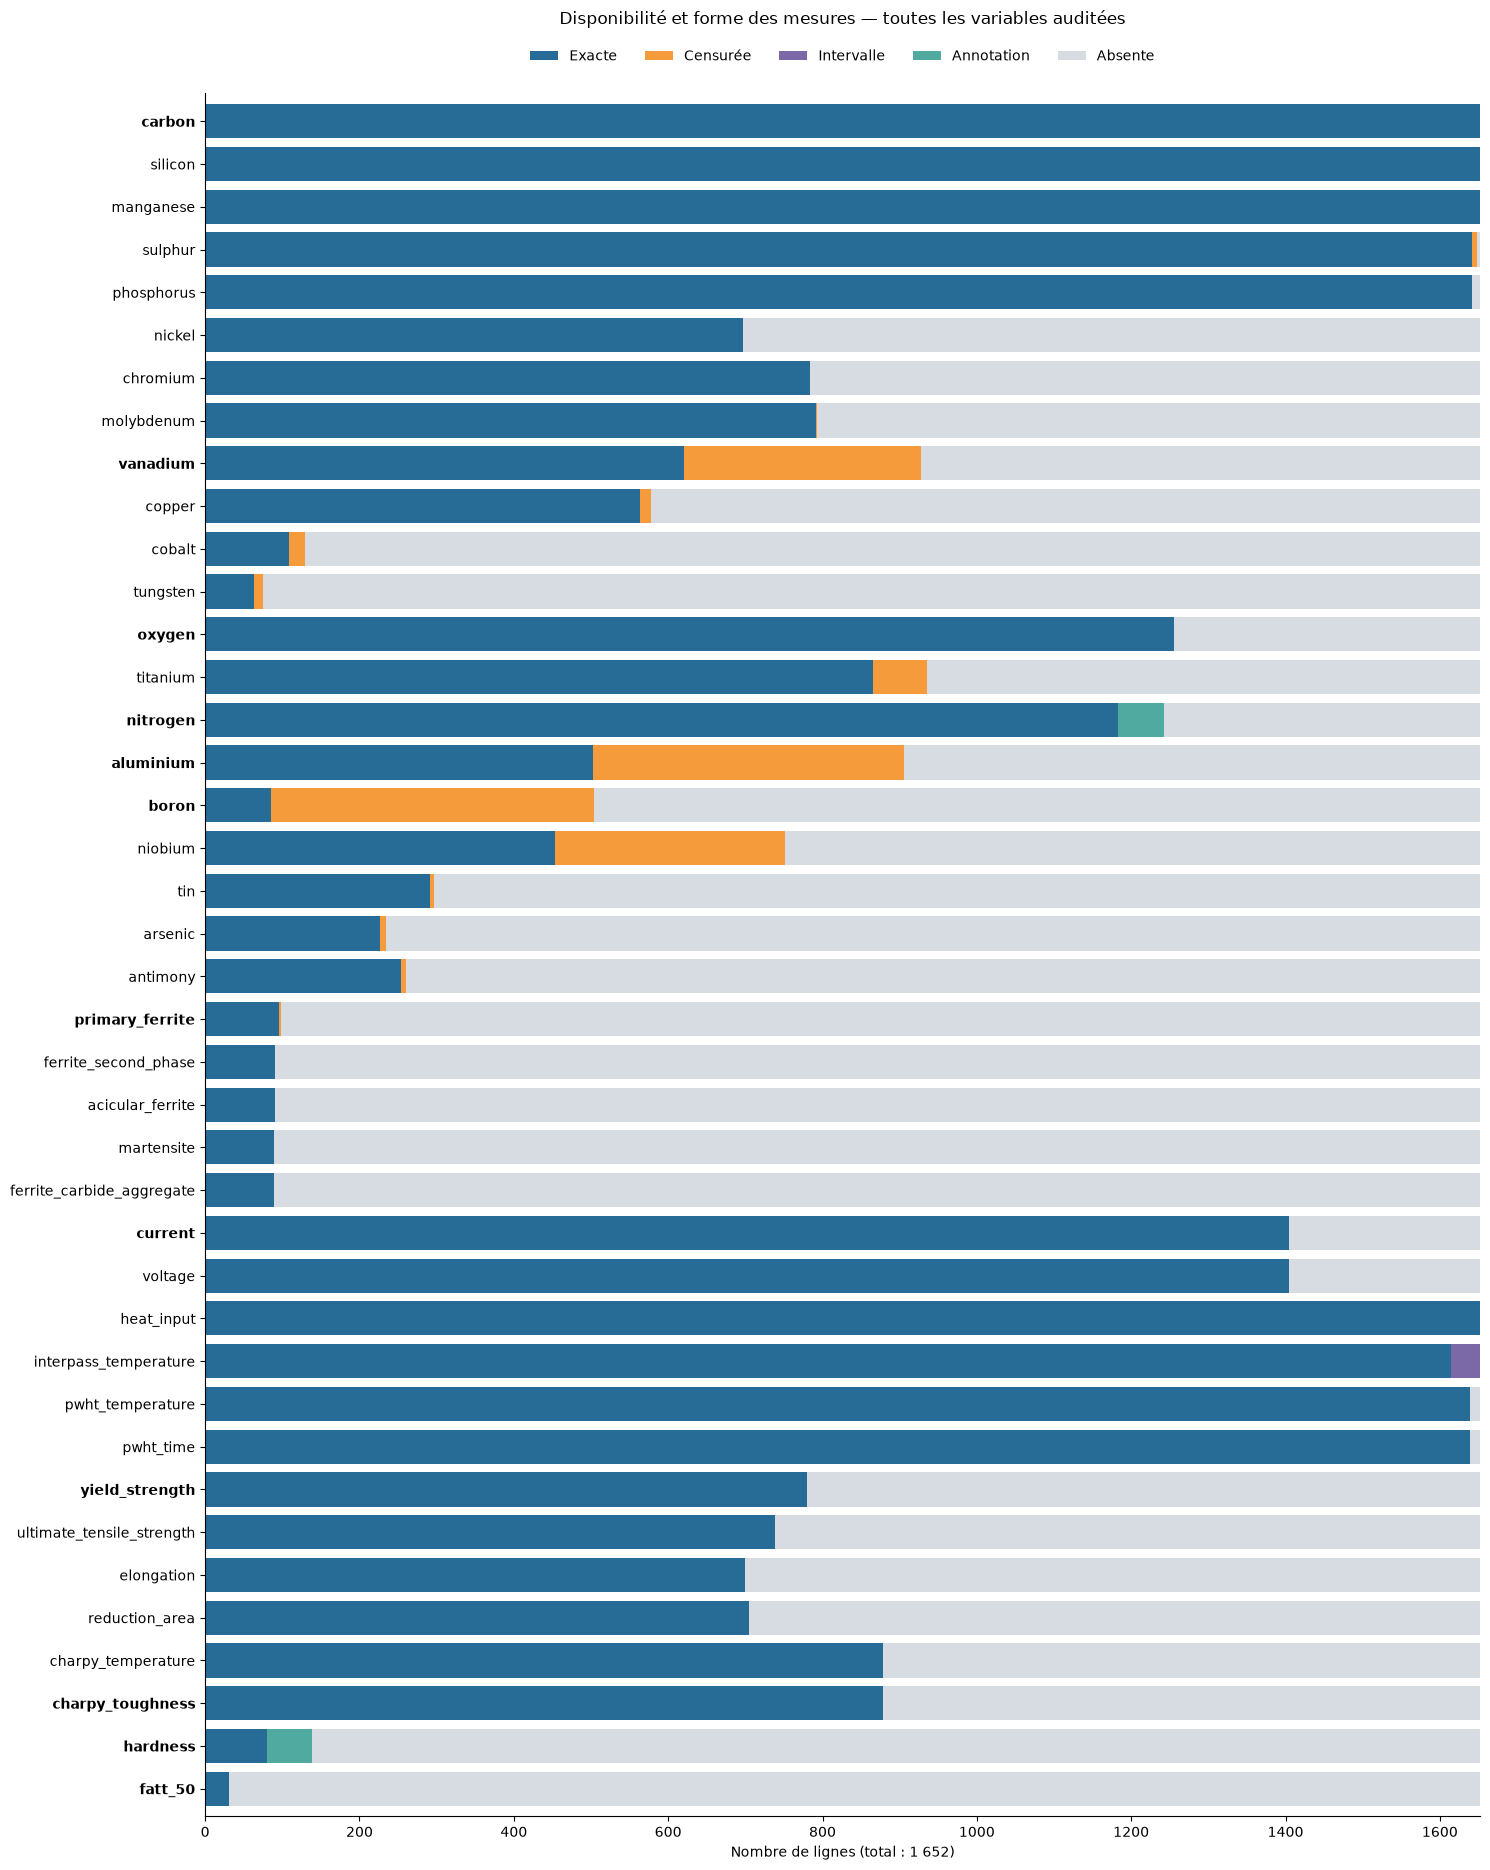

In [7]:
# Effectifs déjà calculés dans summary
counts = summary[
    ["n_exact", "n_censored", "n_interval", "n_annotation", "n_missing"]
].rename(columns={
    "n_exact": "Exacte",
    "n_censored": "Censurée",
    "n_interval": "Intervalle",
    "n_annotation": "Annotation",
    "n_missing": "Absente",
})

# Chaque ligne doit répartir toutes les observations entre les cinq statuts.
assert counts.sum(axis=1).eq(len(df)).all(), (
    "Certains effectifs ne correspondent pas au nombre de lignes de df."
)

ax = counts.plot.barh(
    stacked=True,
    color=["#276c96", "#f59b3b", "#7b68a6", "#50aaa0", "#d7dce2"],
    figsize=(15, 0.42 * len(counts) + 2),
    width=0.8,
)

ax.invert_yaxis()
ax.set_xlim(0, len(df))
ax.set_ylabel("")
ax.set_xlabel(
    f"Nombre de lignes (total : {len(df):,})".replace(",", " ")
)
ax.set_title(
    "Disponibilité et forme des mesures — toutes les variables auditées",
    pad=50,
)
ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=5,
    frameon=False,
)
ax.spines[["top", "right"]].set_visible(False)

# Mettre en évidence les variables de la figure du rapport.
principales = {
    "carbon", "current", "oxygen", "aluminium", "vanadium",
    "boron", "nitrogen", "yield_strength", "charpy_toughness",
    "hardness", "primary_ferrite", "fatt_50",
}
for label in ax.get_yticklabels():
    if label.get_text() in principales:
        label.set_fontweight("bold")

plt.tight_layout()
plt.show()

In [8]:
# No arbitrary upper limits for current, voltage, strength, etc.
bounds = {
    col: (0, np.inf)
    for col in UNITS
    if col != "fatt_50"  # Unit still requires confirmation.
}

bounds.update({
    col: (0, 100)
    for col in wt_pct + microstructure + ["reduction_area"]
})

bounds.update({
    col: (0, 1_000_000)
    for col in ppm
})

bounds.update({
    col: (-273.15, np.inf)
    for col in [
        "interpass_temperature",
        "pwht_temperature",
        "charpy_temperature",
    ]
})

violations = pd.DataFrame(False, index=df.index, columns=UNITS)

for col, (lower, upper) in bounds.items():
    violations[col] = (
        exact[col].notna()
        & ~exact[col].between(lower, upper)
    )

display(
    violations.sum()
    .rename("outside_physical_bounds")
    .to_frame()
)

# Show the original values and weld identifiers for investigation.
for col in violations.columns[violations.any()]:
    print(f"\nOutside physical bounds: {col} [{UNITS[col]}]")
    display(df.loc[violations[col], ["weld_id", col]])

# Cross-variable consistency check where both values are exact.
invalid_strength = (
    exact["yield_strength"].notna()
    & exact["ultimate_tensile_strength"].notna()
    & (
        exact["yield_strength"]
        > exact["ultimate_tensile_strength"]
    )
)

print("Yield strength > tensile strength:", invalid_strength.sum())
display(
    df.loc[
        invalid_strength,
        ["weld_id", "yield_strength", "ultimate_tensile_strength"],
    ]
)

Yield strength > tensile strength: 0


,outside_physical_bounds
carbon,0
silicon,0
manganese,0
sulphur,0
phosphorus,0
nickel,0
chromium,0
molybdenum,0
vanadium,0
copper,0


,weld_id,yield_strength,ultimate_tensile_strength


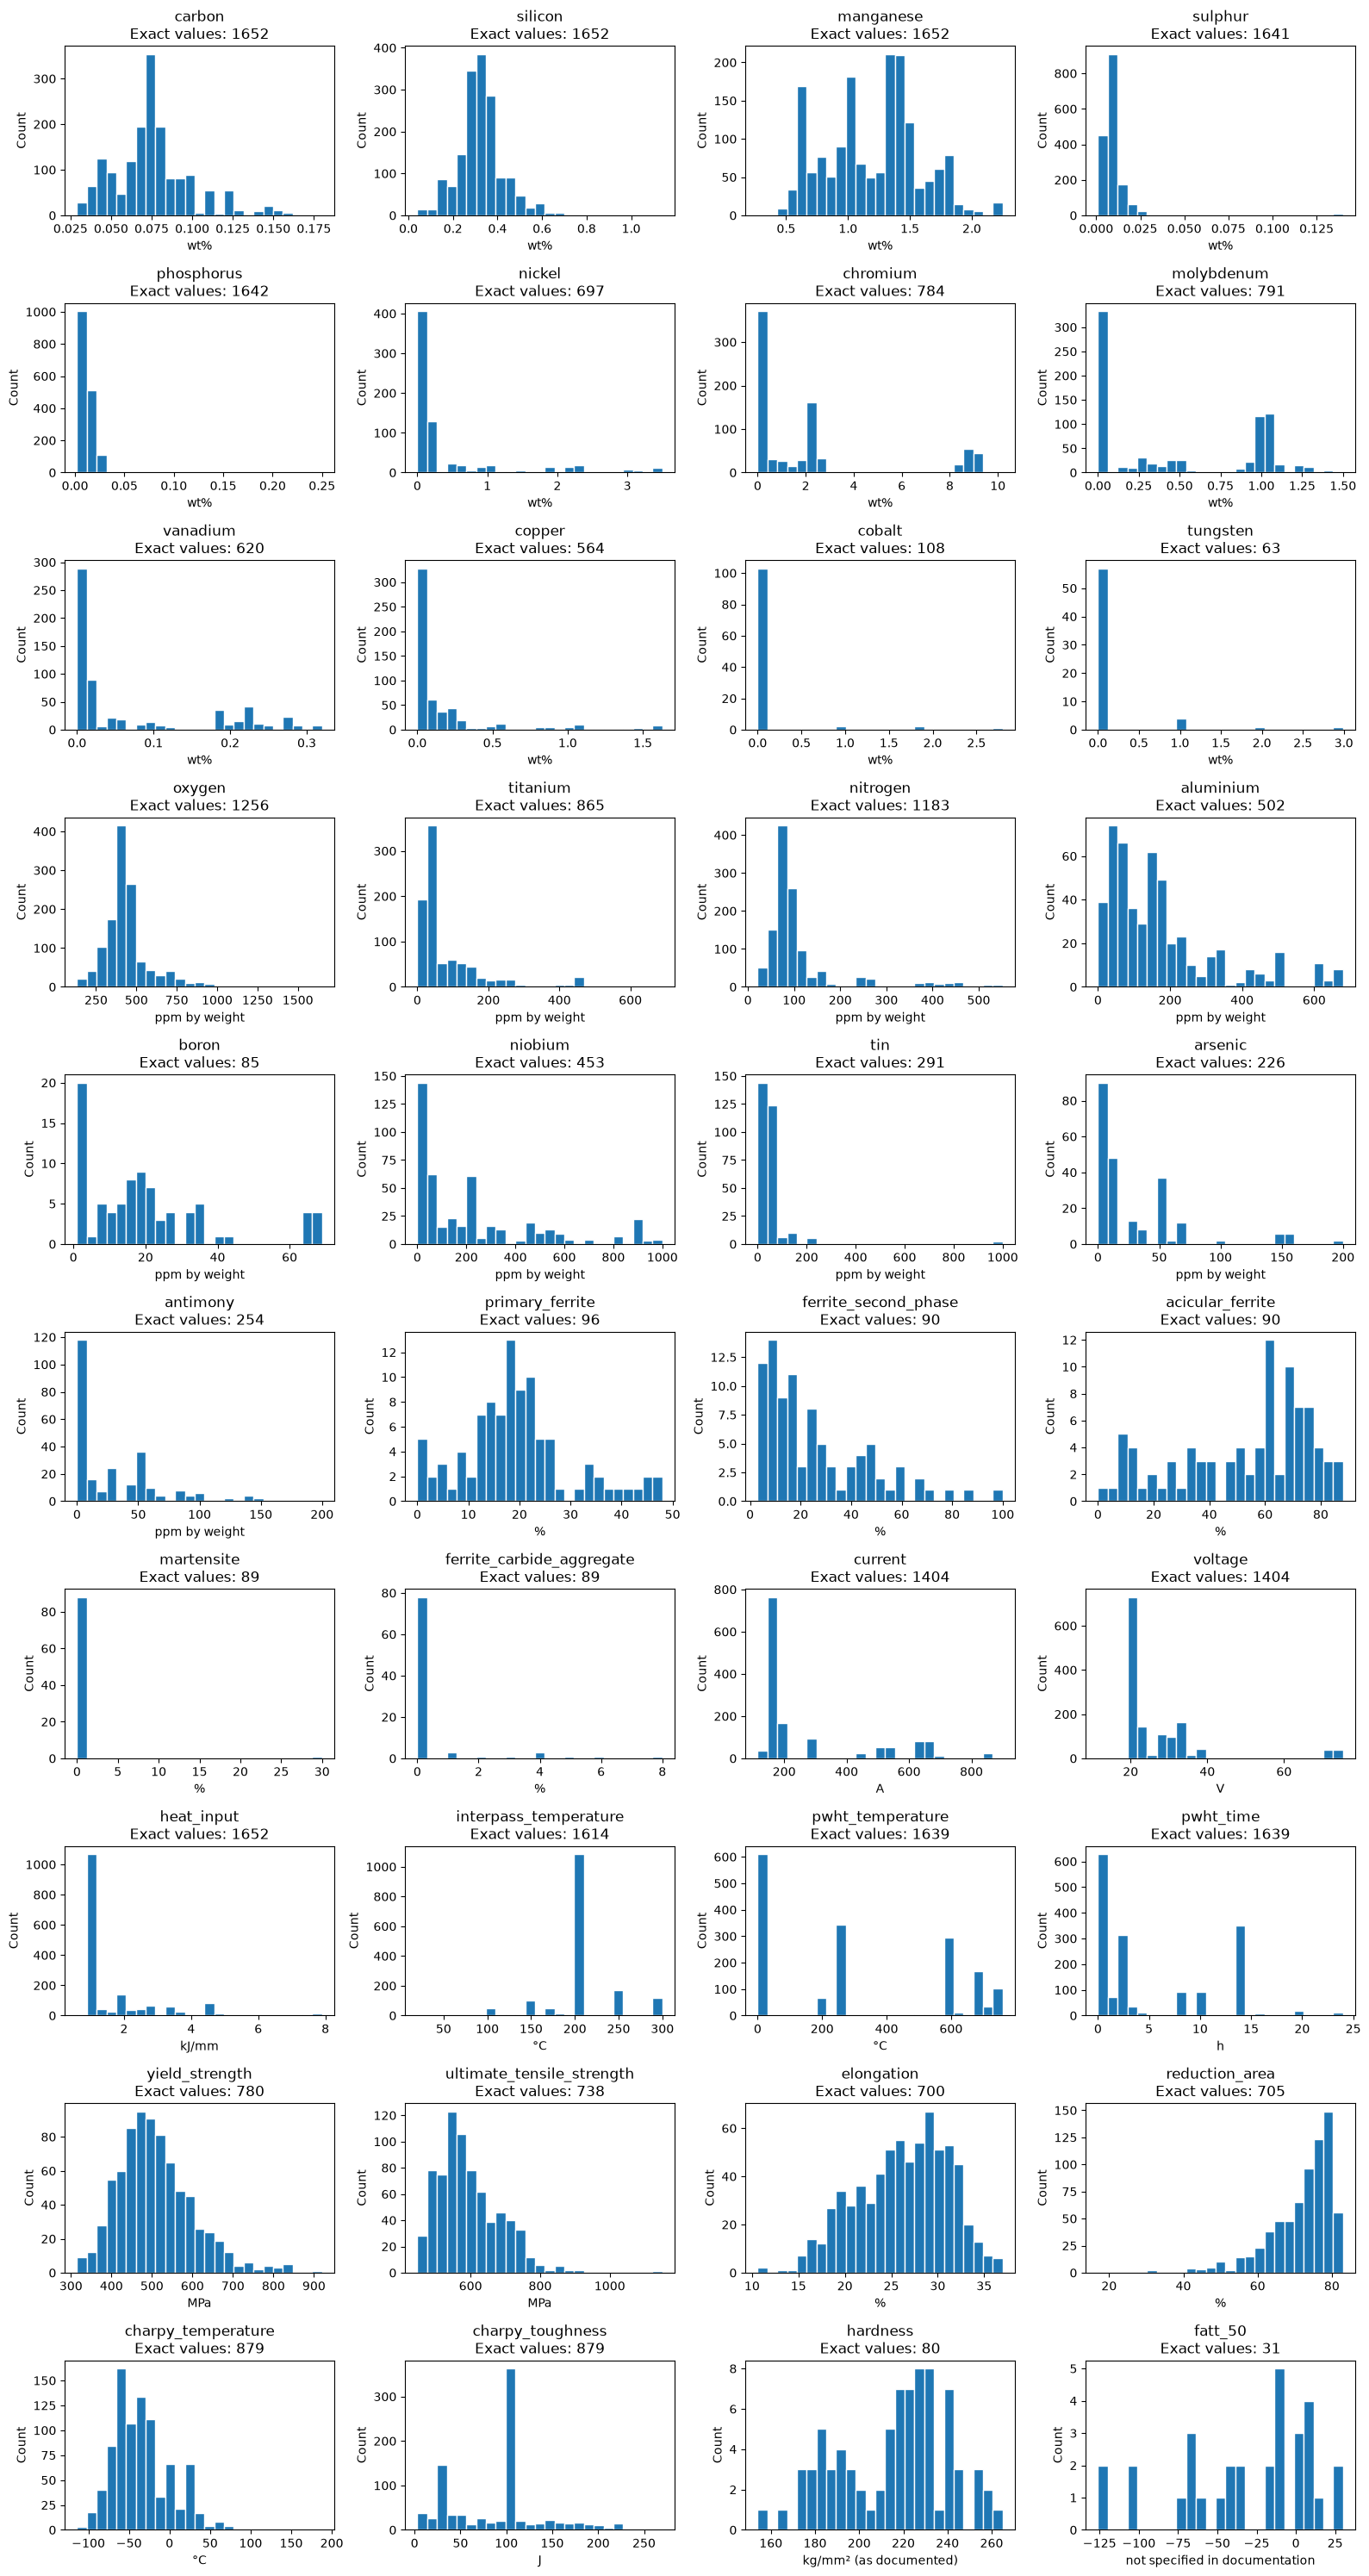

In [9]:
def plot_distributions(columns):
    columns = list(columns)
    nrows = math.ceil(len(columns) / 4)

    fig, axes = plt.subplots(
        nrows, 4,
        figsize=(16, 3 * nrows),
        squeeze=False,
    )

    for ax, col in zip(axes.flat, columns):
        values = exact[col].dropna()

        ax.hist(values, bins=25, edgecolor="white")
        ax.set_title(f"{col}\nExact values: {len(values)}")
        ax.set_xlabel(UNITS[col])
        ax.set_ylabel("Count")

    for ax in axes.flat[len(columns):]:
        ax.set_visible(False)

    fig.tight_layout()
    plt.show()


# All numeric variables:
plot_distributions(UNITS)

# Alternatively, inspect a smaller selection:
# plot_distributions([
#     "aluminium", "titanium", "nitrogen", "oxygen",
#     "current", "voltage", "heat_input", "interpass_temperature",
# ])

In [10]:
# Inspect censored values, intervals and annotations.
for col in UNITS:
    special = status[col].isin([
        "censored", "interval", "annotation / other"
    ])

    if special.any():
        print(f"\nSpecial values: {col}")
        display(df.loc[special, col].value_counts().to_frame("count"))

# Investigate possible magnitude/unit differences in ppm columns.
small_ppm = exact[ppm].gt(0) & exact[ppm].lt(1)

for col in ppm:
    if small_ppm[col].any():
        print(f"\nReview positive values below 1 ppm: {col}")
        display(df.loc[small_ppm[col], ["weld_id", col]])

# Inspect the rows at both extremes of any variable.
def inspect_extremes(col, n=5):
    ordered = exact[col].dropna().sort_values()
    indices = ordered.head(n).index.union(
        ordered.tail(n).index, sort=False
    )
    display(df.loc[indices, ["weld_id", col]])


inspect_extremes("aluminium")
inspect_extremes("current")


Special values: sulphur

Special values: molybdenum

Special values: vanadium

Special values: copper

Special values: cobalt

Special values: tungsten

Special values: titanium

Special values: nitrogen

Special values: aluminium

Special values: boron

Special values: niobium

Special values: tin

Special values: arsenic

Special values: antimony

Special values: primary_ferrite

Special values: interpass_temperature

Special values: hardness

Review positive values below 1 ppm: titanium

Review positive values below 1 ppm: aluminium

Review positive values below 1 ppm: tin

Review positive values below 1 ppm: arsenic

Review positive values below 1 ppm: antimony


,count
sulphur,
<0.002,7


,count
molybdenum,
<0.01,2


,count
vanadium,
<0.0005,266
<0.01,31
<5,9
<0.005,2


,count
copper,
<0.01,14


...

,weld_id,tin
1307,Mart-A,0.009
1308,Mart-Aa,0.009
1309,Mart-Ab,0.009
1310,Mart-Ac,0.009
1311,Mart-Ad,0.009
...,...,...
1430,Ditt-0.5rch3,0.002
1431,Ditt-iat,0.002
1432,Ditt-iatch1,0.002
1433,Ditt-iatch2,0.002


,weld_id,arsenic
1307,Mart-A,0.01
1308,Mart-Aa,0.01
1309,Mart-Ab,0.01
1310,Mart-Ac,0.01
1311,Mart-Ad,0.01
...,...,...
1430,Ditt-0.5rch3,0.003
1431,Ditt-iat,0.003
1432,Ditt-iatch1,0.003
1433,Ditt-iatch2,0.003


,weld_id,antimony
1307,Mart-A,0.008
1308,Mart-Aa,0.008
1309,Mart-Ab,0.008
1310,Mart-Ac,0.008
1311,Mart-Ad,0.008
...,...,...
1430,Ditt-0.5rch3,0.001
1431,Ditt-iat,0.001
1432,Ditt-iatch1,0.001
1433,Ditt-iatch2,0.001


,weld_id,aluminium
1226,EPRI-TR-101394s-E9GT4,0.004
1227,EPRI-TR-101394s-E9GT4,0.004
1228,EPRI-TR-101394s-E9GM2,0.004
1229,EPRI-TR-101394s-E9GM2,0.004
1225,EPRI-TR-101394s-E9GT3,0.005
91,Evans-AlTi-1994-5/660ch1,660
157,Evans-AlTi-1994-220/680ch1,680
158,Evans-AlTi-1994-220/680ch2,680
159,Evans-AlTi-1994-220/680mic,680
156,Evans-AlTi-1994-220/680,680


,weld_id,current
1194,PantK-1990-w7.4,115.0
1195,PantK-1990-w7.5,115.0
1196,PantK-1990-w7.6,115.0
1190,PantK-1990-w7.0,115.0
1191,PantK-1990-w7.1,115.0
1160,Ga&K-1975II-5aw,850.0
1444,p12-RR82011,900.0
1443,p12-RR82011,900.0
1452,p16-RR82011,900.0
1451,p16-RR82011,900.0


### Audit réutilisable et traçabilité

Les cellules précédentes décrivent les jetons du fichier. À partir d'ici, le code
réutilisable est dans `src/weld_quality/`. La lecture indépendante ci-dessous
conserve les chaînes originales et laisse `df` inchangé. Les nombres exacts,
les bornes, les annotations, les cellules à vérifier et les estimations sont séparés.
Les unités suspectes ne sont pas corrigées automatiquement.

In [11]:
from IPython.display import Markdown
from threadpoolctl import threadpool_limits

from weld_quality.schema import CORE_INPUTS, EXTENDED_INPUTS, TENSILE, PROPERTIES, MICROSTRUCTURE
from weld_quality.preprocessing import (
    load_raw, audit_measurements, prepare_matrix, identifier_groups, normalized_process,
)
from weld_quality.exploration import (
    availability_table, observed_pair_counts, benchmark_imputation, benchmark_summary,
    fit_exploratory_pca, pca_sensitivity, export_analysis,
)
from weld_quality.plotting import (
    plot_missingness, plot_observed_correlations, plot_benchmark, plot_ecdfs,
    plot_pca, plot_sensitivity,
)

raw_tokens = load_raw(RAW_DATA_DIR / 'welddb.data')
audit = audit_measurements(raw_tokens)
process = normalized_process(raw_tokens)
group_table = identifier_groups(raw_tokens)
groups = group_table['group']
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def show_and_save(fig, name):
    fig.savefig(FIGURES_DIR / f'{name}.png', dpi=140, bbox_inches='tight')
    display(fig)
    plt.close(fig)


assert raw_tokens.shape == df.shape
assert audit.status.isin(['numeric', 'missing', 'censored', 'interval', 'annotation / other']).all().all()
display(availability_table(audit, groups).round(2))

,role,unit,numeric,censored,interval,annotation / other,missing,review_cells,reported_pct,reported_groups,exact_usable_groups
carbon,input,wt%,1652,0,0,0,0,0,100.00,47,47
silicon,input,wt%,1652,0,0,0,0,0,100.00,47,47
manganese,input,wt%,1652,0,0,0,0,0,100.00,47,47
sulphur,input,wt%,1641,7,0,0,4,0,99.76,46,46
phosphorus,input,wt%,1642,0,0,0,10,0,99.39,46,46
nickel,input,wt%,697,0,0,0,955,0,42.19,26,26
chromium,input,wt%,784,0,0,0,868,0,47.46,29,29
molybdenum,input,wt%,791,2,0,0,859,0,48.00,28,28
vanadium,input,wt%,620,308,0,0,724,9,56.17,24,19
copper,input,wt%,564,14,0,0,1074,0,34.99,20,20


Les petites valeurs en ppm et les limites suspectes sont des **cas à vérifier**,
pas des erreurs confirmées. Dans les scénarios numériques, elles sont rendues
provisoirement indisponibles ; le statut original et le motif restent conservés.
L'extraction des annotations ci-dessous est lexicale : `nd` reste un marqueur,
et les protocoles de dureté ne sont pas fusionnés. Les zéros restent observés.

In [12]:
display(audit.issues.groupby(['variable', 'reason']).size().rename('n').to_frame())
display(audit.issues.head(15))
display(audit.annotations.head(12))
display(audit.annotations.loc[audit.annotations.variable.eq('hardness'),
                              ['row', 'weld_id', 'raw_value', 'extracted_number', 'protocol']].head(10))

n
variable  reason                            
aluminium unit_review_below_1_ppm         10
          unit_review_limit_0.01_ppm      16
antimony  unit_review_below_1_ppm         90
arsenic   unit_review_below_1_ppm         90
tin       unit_review_below_1_ppm         90
titanium  unit_review_below_1_ppm          1
          unit_review_limit_0.01_ppm      16
vanadium  unit_review_limit_5_wt_percent   9

,row,weld_id,variable,raw_value,reason
0,1616,EvansLetterC+.25Mo,vanadium,<5,unit_review_limit_5_wt_percent
1,1617,EvansLetterC+.25Moch1,vanadium,<5,unit_review_limit_5_wt_percent
2,1618,EvansLetterC+.25Moch2,vanadium,<5,unit_review_limit_5_wt_percent
3,1619,EvansLetterC+.5Mo,vanadium,<5,unit_review_limit_5_wt_percent
4,1620,EvansLetterC+.5Moch1,vanadium,<5,unit_review_limit_5_wt_percent
5,1621,EvansLetterC+.5Moch2,vanadium,<5,unit_review_limit_5_wt_percent
6,1622,EvansLetterC+1Mo,vanadium,<5,unit_review_limit_5_wt_percent
7,1623,EvansLetterC+1Moch1,vanadium,<5,unit_review_limit_5_wt_percent
8,1624,EvansLetterC+1Moch2,vanadium,<5,unit_review_limit_5_wt_percent
9,1069,Stil-TiB-1978-1.5Mn/BX200,titanium,0.5,unit_review_below_1_ppm


,row,variable,raw_value,weld_id,tot_token,res_token,extracted_number,protocol
0,274,nitrogen,67tot33res,Evans-Al/CMn-1990-<5aw,67,33,NaN,NaN
1,275,nitrogen,67tot33res,Evans-Al/CMn-1990-<5awch1,67,33,NaN,NaN
2,276,nitrogen,67tot33res,Evans-Al/CMn-1990-<5awch2,67,33,NaN,NaN
3,277,nitrogen,67tot33res,Evans-Al/CMn-1990-<5aw,67,33,NaN,NaN
4,278,nitrogen,67tot33res,Evans-Al/CMn-1990-<5ht,67,33,NaN,NaN
5,279,nitrogen,67tot33res,Evans-Al/CMn-1990-<5htch1,67,33,NaN,NaN
6,280,nitrogen,67tot33res,Evans-Al/CMn-1990-<5htch2,67,33,NaN,NaN
7,281,nitrogen,66totndres,Evans-Al/CMn-1990-20aw,66,nd,NaN,NaN
8,282,nitrogen,66totndres,Evans-Al/CMn-1990-20awch1,66,nd,NaN,NaN
9,283,nitrogen,66totndres,Evans-Al/CMn-1990-20awch2,66,nd,NaN,NaN


,row,weld_id,raw_value,extracted_number,protocol
59,945,Pat-1981-RE2L/BX200,158(Hv30),158.0,Hv30
60,950,Pat-1981-S2/BX200,155(Hv30),155.0,Hv30
61,955,Pat-1981-RE3L/BX200,153(Hv30),153.0,Hv30
62,960,Pat-1981-WB3/BX200,161(Hv30),161.0,Hv30
63,965,Pat-1981-S4/BX200,168(Hv30),168.0,Hv30
64,970,Pat-1981-S6/BX200,203(Hv30),203.0,Hv30
65,975,Pat-1981-S2Mo/BX200,157(Hv30),157.0,Hv30
66,980,Pat-1981-S4Mo/BX200,174(Hv30),174.0,Hv30
67,985,Pat-1981-RE2L/BX400,144(Hv30),144.0,Hv30
68,990,Pat-1981-S2/BX400,144(Hv30),144.0,Hv30


## 3. Understand weld quality and candidate targets

Investigate the physical meaning of potential target properties and which inputs are available at prediction time. Identify label availability for each candidate target.

### Propriétés candidates : explorer des mesures, sans imputer les labels

L'ACP ne définit pas la qualité ni un seuil « bonne/mauvaise soudure ». On examine
les propriétés physiques séparément des entrées. Les corrélations ci-dessous
utilisent les paires mesurées, avec leurs effectifs. Les quatre propriétés de
traction disposent d'un sous-ensemble complet, sans remplissage.

Traction : 650 lignes complètes, sans imputation.


,yield_strength,ultimate_tensile_strength,elongation,reduction_area,charpy_temperature,charpy_toughness,hardness,fatt_50
yield_strength,780,714,691,696,144,144,71,28
ultimate_tensile_strength,714,738,666,671,144,144,55,12
elongation,691,666,700,685,142,142,54,11
reduction_area,696,671,685,705,136,136,55,12
charpy_temperature,144,144,142,136,879,879,0,12
charpy_toughness,144,144,142,136,879,879,0,12
hardness,71,55,54,55,0,0,80,16
fatt_50,28,12,11,12,12,12,16,31


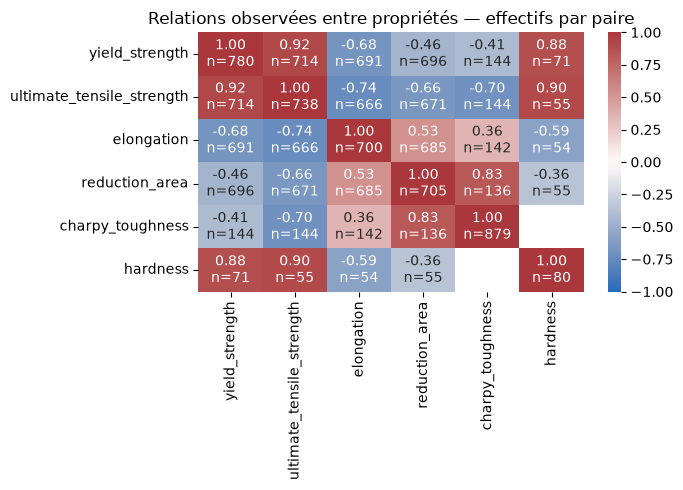

,variance_ratio,cumulative_ratio
PC1,0.7569,0.7569
PC2,0.1471,0.9040
PC3,0.0830,0.9870
PC4,0.0130,1.0000


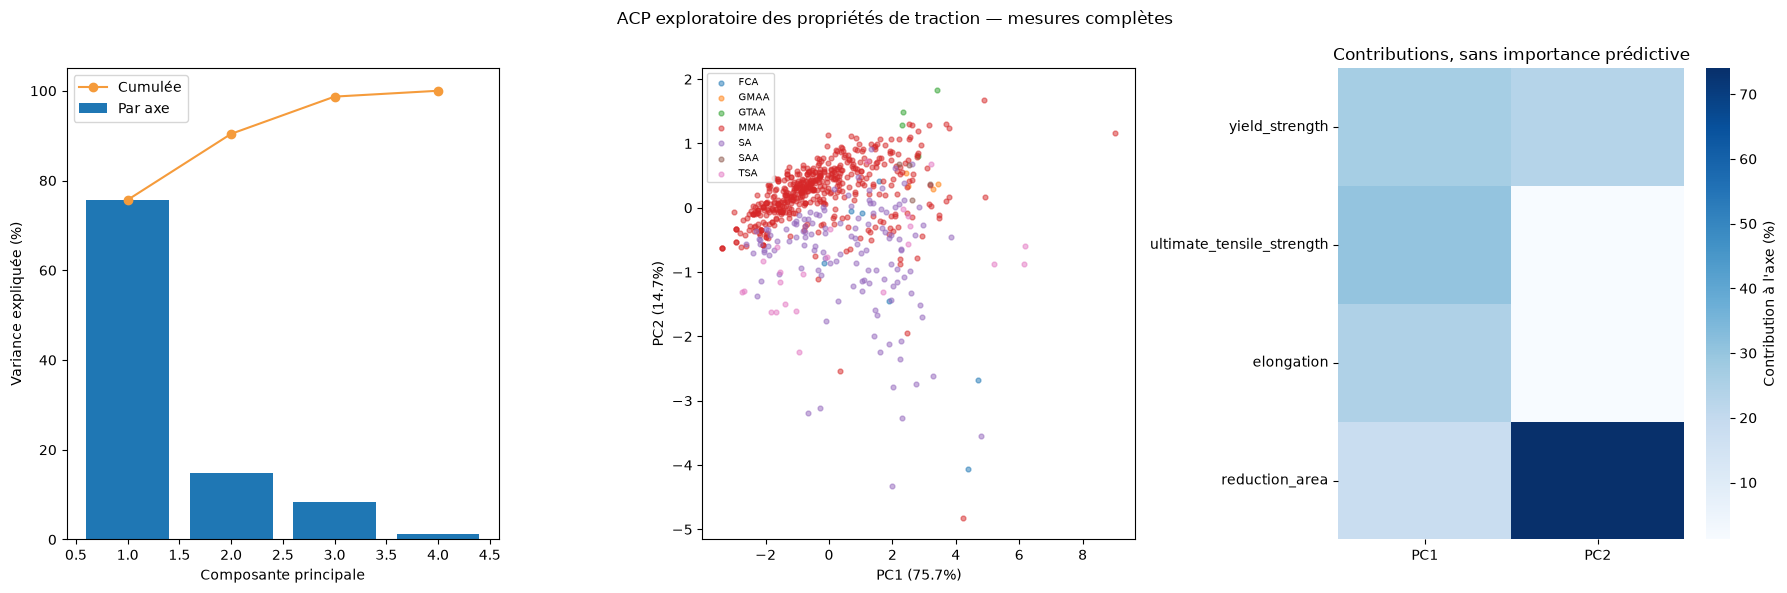

In [13]:
display(observed_pair_counts(audit.exact[PROPERTIES]))
tensile_complete = audit.exact[TENSILE].dropna()
print(f'Traction : {len(tensile_complete)} lignes complètes, sans imputation.')
show_and_save(
    plot_observed_correlations(audit.exact[TENSILE + ['charpy_toughness', 'hardness']],
                              'Relations observées entre propriétés — effectifs par paire'),
    '02_properties_observed_correlations',
)
tensile_pca = fit_exploratory_pca(tensile_complete)
display(tensile_pca.explained.round(4))
show_and_save(plot_pca(tensile_pca, process,
                       'ACP exploratoire des propriétés de traction — mesures complètes'),
              '02_tensile_pca')

L'énergie Charpy doit être interprétée avec la température d'essai. Les fortes
fréquences à certaines énergies et les répétitions de séries demandent un retour
aux publications avant de fixer une tâche de prédiction. La dureté et Charpy
n'ont aucune paire renseignée dans cette base, même avec les annotations de
dureté : on ne reconstruit pas leur relation par une imputation globale.

Microstructure : pas de renormalisation ou d’imputation avant clarification des catégories et sommes.


,n
charpy_toughness,
100.0,356
28.0,118
50.0,16
35.0,12
70.0,12
9.0,8
15.0,7
220.0,7


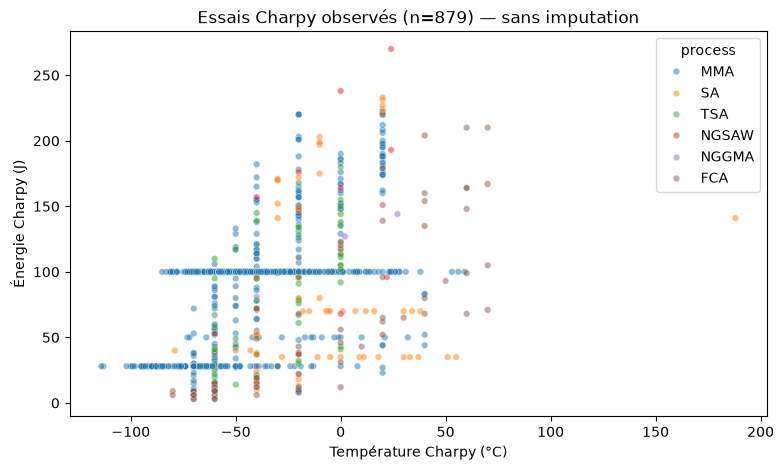

,weld_id,primary_ferrite,ferrite_second_phase,acicular_ferrite,martensite,ferrite_carbide_aggregate,total_pct
10,Evans-Ni/CMn-1990/1991-0Dawch,13,17,60,0,0,90.0
582,Evans-Ti/CMn-1992-P0.1mic,16,21,82,0,0,119.0
606,Evans-Ti/CMn-1992-R2.4ch2,21,11,67,0,0,99.0


In [14]:
charpy = audit.exact[['charpy_temperature', 'charpy_toughness']].dropna()
display(charpy.charpy_toughness.value_counts().head(8).rename('n').to_frame())
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=charpy.assign(process=process.loc[charpy.index]),
                x='charpy_temperature', y='charpy_toughness', hue='process', alpha=.5, s=22, ax=ax)
ax.set(xlabel='Température Charpy (°C)', ylabel='Énergie Charpy (J)',
       title=f'Essais Charpy observés (n={len(charpy)}) — sans imputation')
show_and_save(fig, '02_charpy_temperature_energy')

micro_complete = audit.exact[MICROSTRUCTURE].dropna()
micro_sums = micro_complete.sum(axis=1)
display(raw_tokens.loc[micro_sums.index[micro_sums.ne(100)], ['weld_id'] + MICROSTRUCTURE]
        .assign(total_pct=micro_sums[micro_sums.ne(100)]))
print('Microstructure : pas de renormalisation ou d’imputation avant clarification des catégories et sommes.')

## 4. Explore distributions and relationships

Plot selected feature and target distributions and relationships. Include units and meaningful captions; export report figures to `reports/figures/`.

### Absences conjointes, procédés et séries apparentées

Les profils d'absence sont examinés avant de comparer les imputations. `ShMA`
est regroupé avec `MMA`, conformément à la documentation. Les groupes ci-dessous
sont des séries **déduites des identifiants**, pas des publications confirmées :
préfixe et année, familles explicites `EvansLetter`, `RR82011`, `Mart`, `Ditt`,
`EPRI`, `Birmingham`, `Kik`, et repli sur l'identifiant exact pour les autres.
Les séries reliées par une observation brute identique hors identifiant sont
réunies. Ces groupes sont conservateurs et devront être réévalués pour la tâche finale.

('current', 'voltage') : mêmes absences = True
('pwht_temperature', 'pwht_time') : mêmes absences = True
('charpy_temperature', 'charpy_toughness') : mêmes absences = True
47 groupes de séries ; 1490 identifiants distincts.


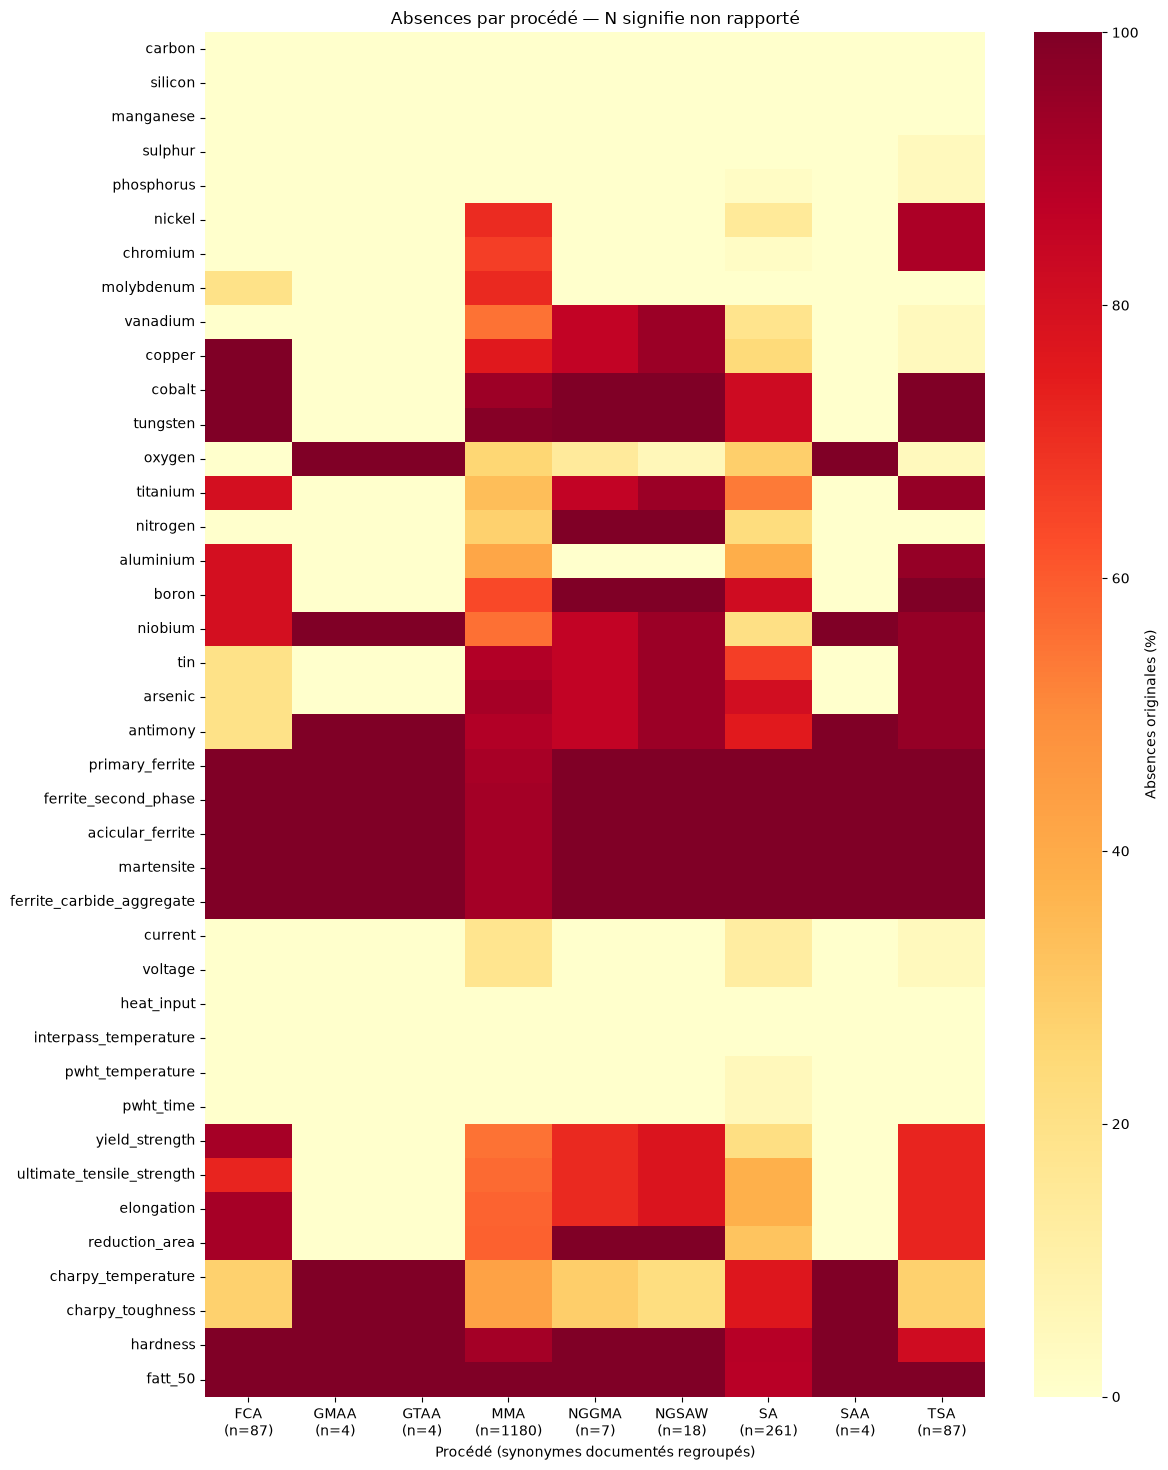

,n_missing,n_joint_with_current,n_joint_with_nickel
carbon,0,0,0
silicon,0,0,0
manganese,0,0,0
sulphur,4,0,0
phosphorus,10,0,6
nickel,955,32,955
chromium,868,32,785
molybdenum,859,32,777
vanadium,724,50,569
copper,1074,32,864


,n_rows,n_identifiers,rule
group,,,
EvansLetter,156,156,letter_family
Evans-Nb/Mn-1991 + Evans-V/Mn-1991,120,120,prefix_and_year+exact_duplicate_link
Evans-AlTi-1994,114,100,prefix_and_year
Evans-StressRelief-1991,110,110,prefix_and_year
SvenGret-1990,96,96,prefix_and_year
Pat-1981,79,16,prefix_and_year
Mart,70,70,explicit_undated_family
Evans-Ti/Mn-1992,60,50,prefix_and_year
Evans-Al/CMn-1990,59,53,prefix_and_year


,weld_id,group,group_rule,identifier_group
333,Evans-V/Mn-1991-A3aw,Evans-Nb/Mn-1991 + Evans-V/Mn-1991,prefix_and_year+exact_duplicate_link,Evans-V/Mn-1991
334,Evans-V/Mn-1991-A3awch,Evans-Nb/Mn-1991 + Evans-V/Mn-1991,prefix_and_year+exact_duplicate_link,Evans-V/Mn-1991
335,Evans-V/Mn-1991-A3ht,Evans-Nb/Mn-1991 + Evans-V/Mn-1991,prefix_and_year+exact_duplicate_link,Evans-V/Mn-1991
336,Evans-V/Mn-1991-A210aw,Evans-Nb/Mn-1991 + Evans-V/Mn-1991,prefix_and_year+exact_duplicate_link,Evans-V/Mn-1991
337,Evans-V/Mn-1991-A210awch,Evans-Nb/Mn-1991 + Evans-V/Mn-1991,prefix_and_year+exact_duplicate_link,Evans-V/Mn-1991
338,Evans-V/Mn-1991-A210ht,Evans-Nb/Mn-1991 + Evans-V/Mn-1991,prefix_and_year+exact_duplicate_link,Evans-V/Mn-1991
339,Evans-V/Mn-1991-A435aw,Evans-Nb/Mn-1991 + Evans-V/Mn-1991,prefix_and_year+exact_duplicate_link,Evans-V/Mn-1991
340,Evans-V/Mn-1991-A435awch,Evans-Nb/Mn-1991 + Evans-V/Mn-1991,prefix_and_year+exact_duplicate_link,Evans-V/Mn-1991
341,Evans-V/Mn-1991-A435ht,Evans-Nb/Mn-1991 + Evans-V/Mn-1991,prefix_and_year+exact_duplicate_link,Evans-V/Mn-1991
342,Evans-V/Mn-1991-A600aw,Evans-Nb/Mn-1991 + Evans-V/Mn-1991,prefix_and_year+exact_duplicate_link,Evans-V/Mn-1991


In [15]:
show_and_save(plot_missingness(audit, process), '02_missingness_by_process')
missing = audit.status.eq('missing')
display(pd.DataFrame({
    'n_missing': missing.sum(),
    'n_joint_with_current': missing.T.dot(missing['current'].astype(int)),
    'n_joint_with_nickel': missing.T.dot(missing['nickel'].astype(int)),
}))
for pair in [('current', 'voltage'), ('pwht_temperature', 'pwht_time'),
             ('charpy_temperature', 'charpy_toughness')]:
    print(pair, ': mêmes absences =', missing[pair[0]].equals(missing[pair[1]]))

group_summary = group_table.groupby('group').agg(
    n_rows=('weld_id', 'size'), n_identifiers=('weld_id', 'nunique'),
    rule=('group_rule', lambda s: ', '.join(sorted(set(s)))),
).sort_values('n_rows', ascending=False)
print(f'{groups.nunique()} groupes de séries ; {raw_tokens.weld_id.nunique()} identifiants distincts.')
display(group_summary)
display(group_table.loc[group_table.group.ne(group_table.identifier_group)].drop_duplicates('weld_id').head(10))

## 5. Preprocessing and PCA

Justify imputation, scaling, exclusions, and transformations. Explore PCA and explained variance. Exploratory fits on the full dataset must not be reused to score predictive models; refit preprocessing within each training fold.

### 5.1 Matrices numériques et origine de chaque cellule

Noyau : onze entrées relativement disponibles. Extension : oxygène, azote et
éléments d'alliage additionnels. La sélection sert à limiter la dépendance au
remplissage ; elle ne mesure pas une importance métallurgique.

Référence descriptive : `<L` devient `L/2` dans les concentrations non négatives
sans drapeau d'unité, et `150-200` devient 175 °C. Ce sont des **approximations**.
Les annotations d'azote et les cellules à vérifier restent indisponibles ; une
éventuelle estimation est tracée comme telle. Leurs nombres bruts ne sont pas
réinterprétés. Les paramètres PWHT nuls sont conservés sans déclarer confirmé
le sens « sans traitement » ; une ACP sans PWHT est également produite.

In [16]:
prepared = {}
provenances = {}
eligibilities = {}
for family, cols in [('core', CORE_INPUTS), ('extended', EXTENDED_INPUTS)]:
    values, provenance = prepare_matrix(audit, cols)
    prepared[family] = values
    provenances[family] = provenance
    eligibilities[family] = provenance.eq('numeric')
    print(f'{family} : {len(cols)} variables, {values.isna().sum().sum()} cellules à estimer.')
    display(pd.DataFrame({
        'n_exact_usable': provenance.eq('numeric').sum(),
        'n_censor_approximation': provenance.eq('censor_approximation').sum(),
        'n_interval_approximation': provenance.eq('interval_approximation').sum(),
        'n_unresolved_review': provenance.eq('unresolved_review').sum(),
        'n_unresolved_annotation': provenance.eq('annotation / other').sum(),
        'n_original_missing': provenance.eq('missing').sum(),
    }))

core : 11 variables, 536 cellules à estimer.
extended : 22 variables, 9445 cellules à estimer.


,n_exact_usable,n_censor_approximation,n_interval_approximation,n_unresolved_review,n_unresolved_annotation,n_original_missing
carbon,1652,0,0,0,0,0
silicon,1652,0,0,0,0,0
manganese,1652,0,0,0,0,0
sulphur,1641,7,0,0,0,4
phosphorus,1642,0,0,0,0,10
current,1404,0,0,0,0,248
voltage,1404,0,0,0,0,248
heat_input,1652,0,0,0,0,0
interpass_temperature,1614,0,38,0,0,0
pwht_temperature,1639,0,0,0,0,13


,n_exact_usable,n_censor_approximation,n_interval_approximation,n_unresolved_review,n_unresolved_annotation,n_original_missing
carbon,1652,0,0,0,0,0
silicon,1652,0,0,0,0,0
manganese,1652,0,0,0,0,0
sulphur,1641,7,0,0,0,4
phosphorus,1642,0,0,0,0,10
current,1404,0,0,0,0,248
voltage,1404,0,0,0,0,248
heat_input,1652,0,0,0,0,0
interpass_temperature,1614,0,38,0,0,0
pwht_temperature,1639,0,0,0,0,13


### 5.2 Vérification par masquage dans des groupes réservés

Trois méthodes : médiane globale, médiane par procédé (au moins trois groupes
observés par variable, sinon repli global), et imputation itérative BayesianRidge
avec le procédé encodé et une échelle ajustée sur l'entraînement. Les estimations
respectent les bornes physiques générales ; les mesures conservées ne changent pas.
Les couples PWHT manquants sont projetés sur des couples réellement observés
dans l'entraînement. Une observation partielle sans couple compatible est refusée.

Trois plis par séries, graines 42 et 43, taux 10/20/40 %, masques de cellules et
de blocs resamplés depuis les seules absences des plis d'entraînement. PWHT est
masqué conjointement. Seuls les nombres exacts sans drapeau sont utilisés comme
vérité cachée ; on ne score pas les substitutions de censure. Les masques et plis
sont identiques entre méthodes. Les vraies absences peuvent suivre un autre mécanisme.

Les MAE/RMSE sont calculées par variable dans leur unité. Le score synthétique
est une moyenne par variable de MAE/IQR d'entraînement (repli sur l'écart-type,
et score normalisé indéfini si les deux sont nuls). Il ne définit pas un gagnant
scientifique : distributions, corrélations et ACP doivent aussi être examinées.

La limite d’itérations a été portée de 20 à 100 après le premier contrôle. Les
échecs de convergence restent affichés ; un résultat non convergé est un
scénario de diagnostic, pas une méthode retenue. Les barres d’erreur représentent
l’écart-type entre plis/graines, pas un intervalle de confiance.

La RMSE des scores PC1/PC2 utilise une ACP et une échelle ajustées sur les
seules lignes exactes complètes d’entraînement. Les lignes réservées sont
uniquement transformées. Cette métrique reste indéfinie sans support complet.


In [17]:
BENCHMARK_CONFIG = dict(
    n_splits=3, seeds=(42, 43), rates=(0.1, 0.2, 0.4),
    patterns=('cells', 'blocks'), max_iter=100,
)
benchmarks = {}
with threadpool_limits(limits=1):
    for family in prepared:
        print(f'Comparaison : {family}')
        benchmarks[family] = benchmark_imputation(
            prepared[family], eligibilities[family], process, groups,
            **BENCHMARK_CONFIG, progress=print,
        )
        display(benchmarks[family].fits)
        display(benchmark_summary(benchmarks[family].metrics).round(4))

Comparaison : core
Fold 1/3 completed (1101 train, 551 verification).
Fold 2/3 completed (1101 train, 551 verification).
Fold 3/3 completed (1102 train, 550 verification).
Comparaison : extended
Fold 1/3 completed (1101 train, 551 verification).
Fold 2/3 completed (1101 train, 551 verification).
Fold 3/3 completed (1102 train, 550 verification).


,fold,method,state,error,converged,iterations
0,0,median,ok,,True,0
1,0,process_median,ok,,True,0
2,0,iterative,ok,,True,3
3,1,median,ok,,True,0
4,1,process_median,ok,,True,0
5,1,iterative,ok,,True,4
6,2,median,ok,,True,0
7,2,process_median,ok,,True,0
8,2,iterative,ok,,True,21


normalized_mae  ...  evaluated_rows
method         pattern rate                  ...                
iterative      blocks  0.1           0.6687  ...              30
                       0.2           0.8472  ...              66
                       0.4           0.8593  ...              66
               cells   0.1           0.8865  ...              66
                       0.2           0.8669  ...              66
                       0.4           0.8901  ...              66
median         blocks  0.1           2.3578  ...              30
                       0.2           1.6836  ...              66
                       0.4           1.6090  ...              66
               cells   0.1           1.6911  ...              66
                       0.2           1.5119  ...              66
                       0.4           1.6872  ...              66
process_median blocks  0.1           1.5070  ...              30
                       0.2           1.2842  ...              66
                       0.4           1.2010  ...              66
               cells   0.1           1.2952  ...              66
                       0.2           1.1149  ...              66
                       0.4           1.2600  ...              66

[18 rows x 4 columns]

,fold,method,state,error,converged,iterations
0,0,median,ok,,True,0
1,0,process_median,ok,,True,0
2,0,iterative,ok,,False,100
3,1,median,ok,,True,0
4,1,process_median,ok,,True,0
5,1,iterative,ok,,False,100
6,2,median,ok,,True,0
7,2,process_median,ok,,True,0
8,2,iterative,ok,,False,100


normalized_mae  ...  evaluated_rows
method         pattern rate                  ...                
iterative      blocks  0.1           2.1573  ...              91
                       0.2           2.0875  ...              94
                       0.4           1.7957  ...             132
               cells   0.1           2.1830  ...             132
                       0.2           2.1036  ...             132
                       0.4           1.7951  ...             132
median         blocks  0.1           2.5805  ...              91
                       0.2           2.6496  ...              94
                       0.4           2.0932  ...             132
               cells   0.1           2.2109  ...             132
                       0.2           2.1131  ...             132
                       0.4           2.0877  ...             132
process_median blocks  0.1           2.4114  ...              91
                       0.2           2.4471  ...              94
                       0.4           1.9053  ...             132
               cells   0.1           2.0283  ...             132
                       0.2           1.9053  ...             132
                       0.4           1.8828  ...             132

[18 rows x 4 columns]

Relations : mêmes paires exactes avant et après reconstruction, n >= 20.
Scores par procédé (MAE normalisée, moyenne par variable/fold/seed/scénario) :
Relations : mêmes paires exactes avant et après reconstruction, n >= 20.
Scores par procédé (MAE normalisée, moyenne par variable/fold/seed/scénario) :


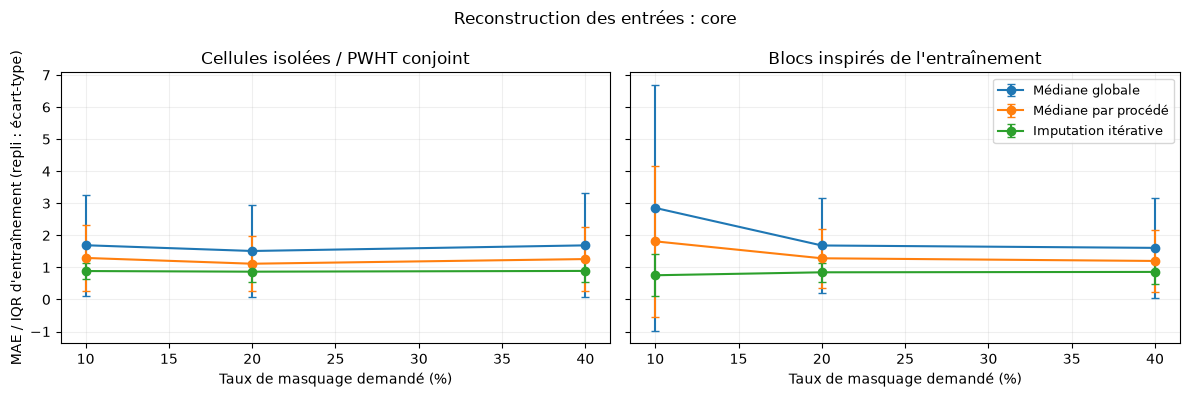

n_masked  ...  normalized_mae
variable              method                    ...                
carbon                iterative           3252  ...          0.8545
                      median              3252  ...          0.7761
                      process_median      3252  ...          0.8096
current               iterative           8587  ...          1.3229
                      median              8587  ...          8.8715
                      process_median      8587  ...          5.0439
heat_input            iterative           3393  ...          0.9453
                      median              3393  ...          1.7117
                      process_median      3393  ...          1.3259
interpass_temperature iterative           3111  ...          1.3954
                      median              3111  ...          0.7965
                      process_median      3111  ...          0.9034
manganese             iterative           3291  ...          0.6726
                      median              3291  ...          0.7007
                      process_median      3291  ...          0.6840
phosphorus            iterative           3624  ...          0.8449
                      median              3624  ...          0.9919
                      process_median      3624  ...          0.8901
pwht_temperature      iterative           3545  ...          0.4113
                      median              3545  ...          0.4312
                      process_median      3545  ...          0.4537
pwht_time             iterative           3545  ...          0.4213
                      median              3545  ...          0.3905
                      process_median      3545  ...          0.3911
silicon               iterative           3175  ...          1.0855
                      median              3175  ...          0.9262
                      process_median      3175  ...          0.9188
sulphur               iterative           3554  ...          1.0407
                      median              3554  ...          1.2984
                      process_median      3554  ...          1.2109
voltage               iterative           8651  ...          0.4675
                      median              8651  ...          1.0080
                      process_median      8651  ...          0.7972

[33 rows x 4 columns]

,mean_abs_correlation_delta,max_abs_correlation_delta,pca_score_rmse
method,,,
iterative,0.0663,0.3347,0.5310
median,0.0840,0.4796,1.0788
process_median,0.0692,0.3172,0.9806


method,iterative,median,process_median
stratum,,,
FCA,1.620,1.914,1.914
GMAA,2.136,2.428,2.428
GTAA,1.526,3.077,3.077
MMA,0.542,0.421,0.404
NGGMA,1.295,1.292,1.292
NGSAW,1.246,2.704,2.704
SA,1.266,3.171,1.667
SAA,1.272,4.467,4.467
TSA,1.581,4.482,4.482


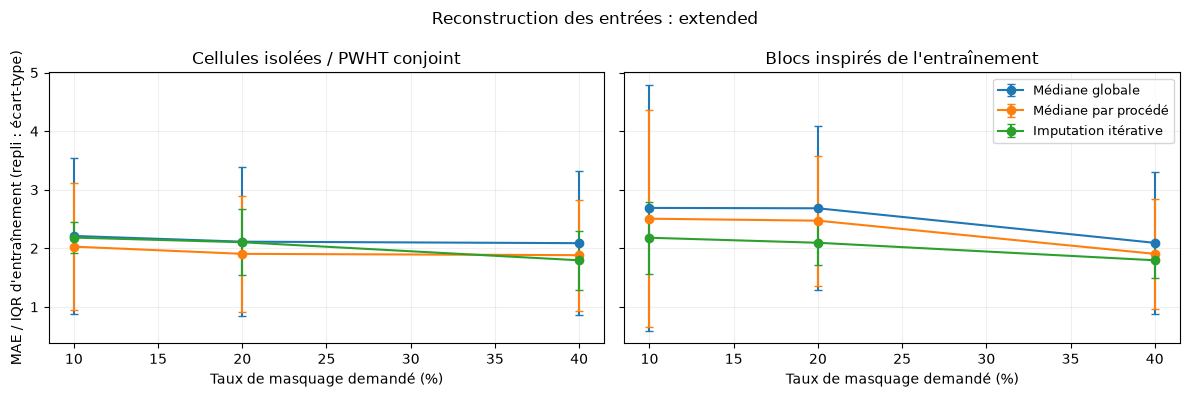

n_masked       mae      rmse  normalized_mae
variable  method                                                      
aluminium iterative           1740  164.6275  232.8674          1.1607
          median              1740  145.7186  201.6794          1.0482
          process_median      1740  133.2712  192.2699          0.9688
boron     iterative            388   21.8164   33.4003          8.9451
          median               388   18.7494   23.1800         12.6624
...                            ...       ...       ...             ...
vanadium  median              2224    0.0964    0.1232          4.0477
          process_median      2224    0.1015    0.1270          4.1601
voltage   iterative           3388    4.4266    7.9238          0.5058
          median              3388    7.9350   12.2459          0.9983
          process_median      3388    6.2908   11.5527          0.8061

[66 rows x 4 columns]

,mean_abs_correlation_delta,max_abs_correlation_delta,pca_score_rmse
method,,,
iterative,0.1589,0.9042,NaN
median,0.1060,0.6686,NaN
process_median,0.1063,0.6951,NaN


method,iterative,median,process_median
stratum,,,
FCA,2.427,1.660,1.660
GMAA,1.850,1.559,1.559
GTAA,5.179,2.038,2.038
MMA,1.419,1.229,1.251
NGGMA,1.087,0.873,0.873
NGSAW,0.954,1.223,1.223
SA,1.943,2.556,1.722
SAA,2.354,2.561,2.561
TSA,4.503,2.940,2.940


In [18]:
for family, result in benchmarks.items():
    show_and_save(plot_benchmark(result.metrics, f'Reconstruction des entrées : {family}'),
                  f'02_reconstruction_{family}')
    all_scores = result.metrics.loc[result.metrics.scope.eq('all')]
    display(all_scores.groupby(['variable', 'method']).agg(
        n_masked=('n', 'sum'), mae=('mae', 'mean'), rmse=('rmse', 'mean'),
        normalized_mae=('normalized_mae', 'mean'),
    ).round(4))
    print('Relations : mêmes paires exactes avant et après reconstruction, n >= 20.')
    display(result.relations.groupby('method')[
        ['mean_abs_correlation_delta', 'max_abs_correlation_delta', 'pca_score_rmse']
    ].mean().round(4))
    print('Scores par procédé (MAE normalisée, moyenne par variable/fold/seed/scénario) :')
    display(result.metrics.loc[result.metrics.scope.eq('process')].pivot_table(
        index='stratum', columns='method', values='normalized_mae', aggfunc='mean',
    ).round(3))

### 5.3 ACP descriptive et sensibilité aux choix de préparation

Chaque scénario est ajusté sur la base entière **uniquement pour l'exploration**.
Ces imputers, échelles et ACP ne doivent pas être réutilisés pour évaluer un modèle.
Le pipeline prédictif devra les réajuster dans chaque pli d'entraînement, avec
les seules entrées disponibles au moment de la prédiction.

On compare les trois méthodes, les substitutions de censure `0`, `L/2`, `L/√2`,
les températures 150/175/200 °C, et les sous-ensembles complets exacts lorsqu'ils
existent. Une ACP sans PWHT traite la sensibilité au sens encore incertain de ses
zéros ; elle a un espace de variables différent, donc aucun angle direct n'est calculé.
Les angles de sous-espaces PC1–PC2 sont invariants aux signes et aux rotations.
Les écarts avec les cas complets reflètent aussi la sélection des observations.
Les indicateurs d'absence et les catégories sont des informations supplémentaires,
pas des variables ajoutées automatiquement à l'ACP physique.

,family,scenario,n_rows,converged,iterations,max_angle_degrees,projector_distance,first_two_variance,aligned_direction_delta
0,core,core_median_half_midpoint,1652,True,0,0.0000,0.0000,0.4541,0.0000
1,core,core_process_median_half_midpoint,1652,True,0,1.9911,0.0562,0.4521,0.0201
2,core,core_iterative_half_midpoint,1652,True,17,2.8148,0.0727,0.4544,0.0303
3,core,core_median_zero_midpoint,1652,True,0,0.0219,0.0006,0.4541,0.0002
4,core,core_median_sqrt2_midpoint,1652,True,0,0.0087,0.0002,0.4541,0.0001
5,core,core_median_half_lower,1652,True,0,0.3647,0.0101,0.4542,0.0039
6,core,core_median_half_upper,1652,True,0,0.3279,0.0104,0.4537,0.0049
7,core,core_complete_exact,1343,True,0,6.0964,0.1691,0.4603,0.0535
8,core,core_without_pwht,1652,True,0,NaN,NaN,0.5288,NaN
9,extended,extended_median_half_midpoint,1652,True,0,0.0000,0.0000,0.3408,0.0000


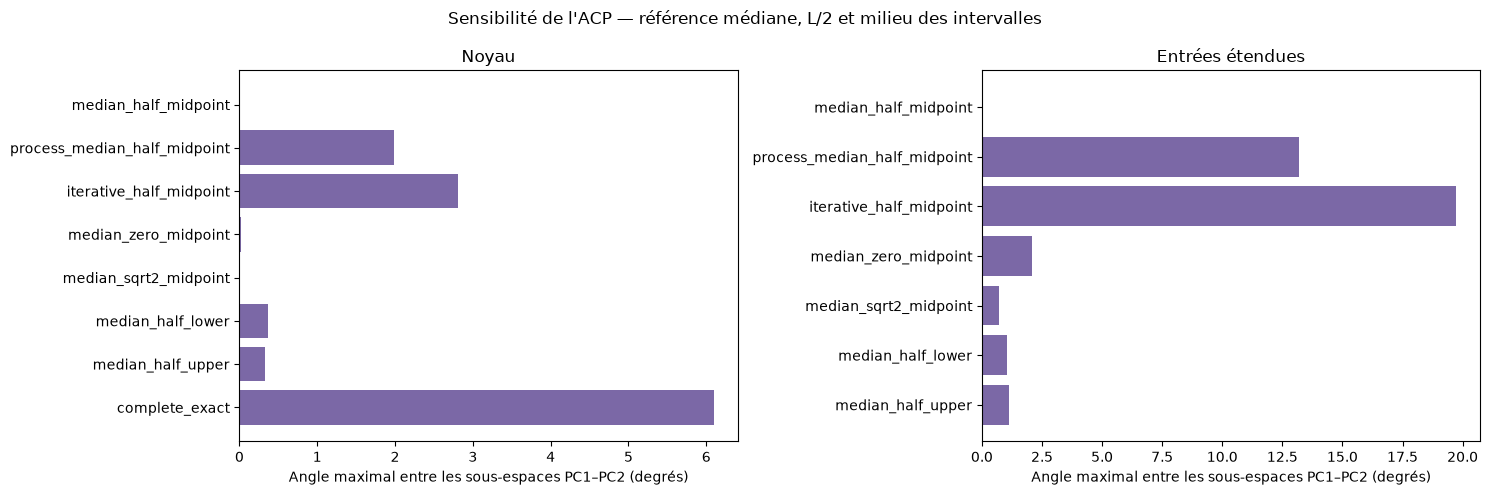

,variance_ratio,cumulative_ratio
PC1,0.2756,0.2756
PC2,0.1785,0.4541
PC3,0.1472,0.6013
PC4,0.0931,0.6943
PC5,0.0780,0.7723
PC6,0.0669,0.8393
PC7,0.0636,0.9029
PC8,0.0474,0.9502
PC9,0.0352,0.9854
PC10,0.0099,0.9954


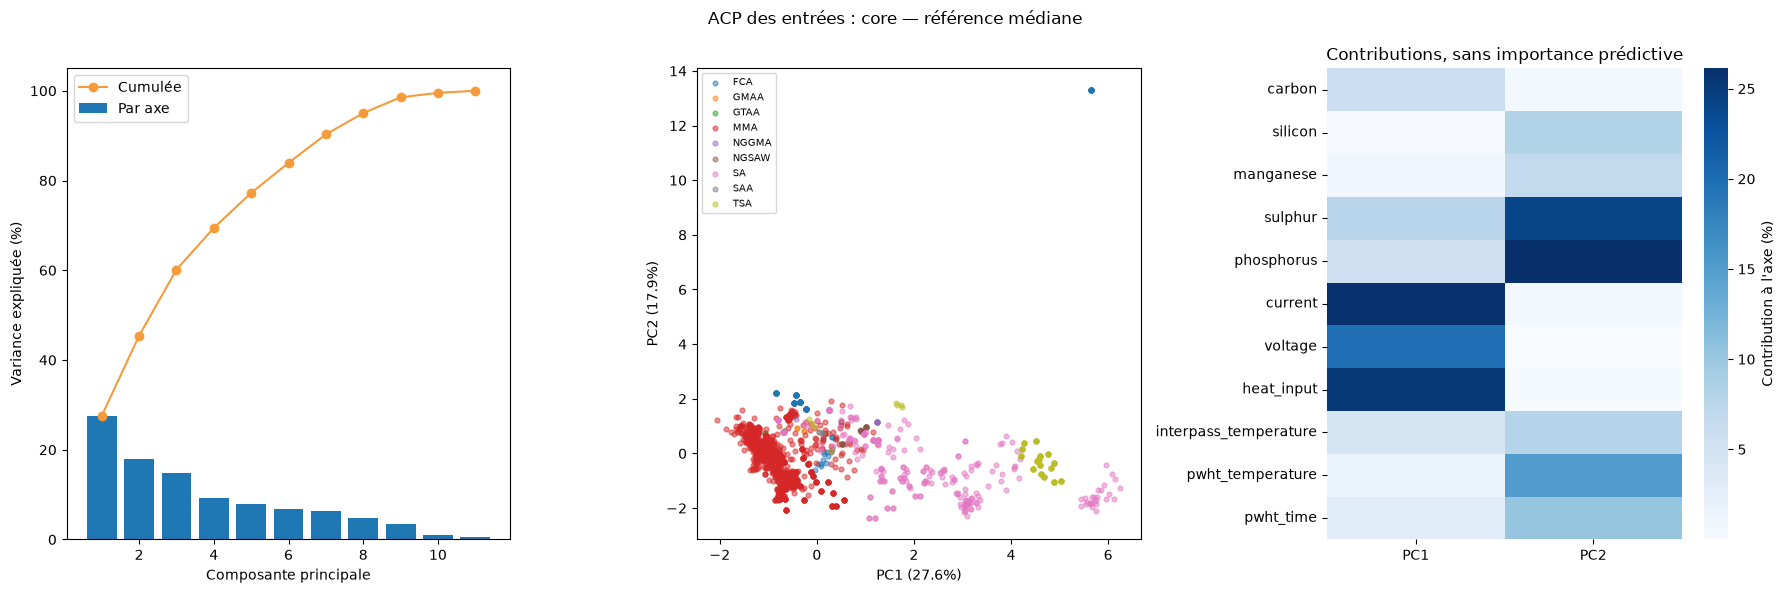

,variance_ratio,cumulative_ratio
PC1,0.1988,0.1988
PC2,0.1420,0.3408
PC3,0.0920,0.4328
PC4,0.0792,0.5120
PC5,0.0613,0.5733
PC6,0.0564,0.6297
PC7,0.0440,0.6737
PC8,0.0423,0.7160
PC9,0.0384,0.7544
PC10,0.0362,0.7906


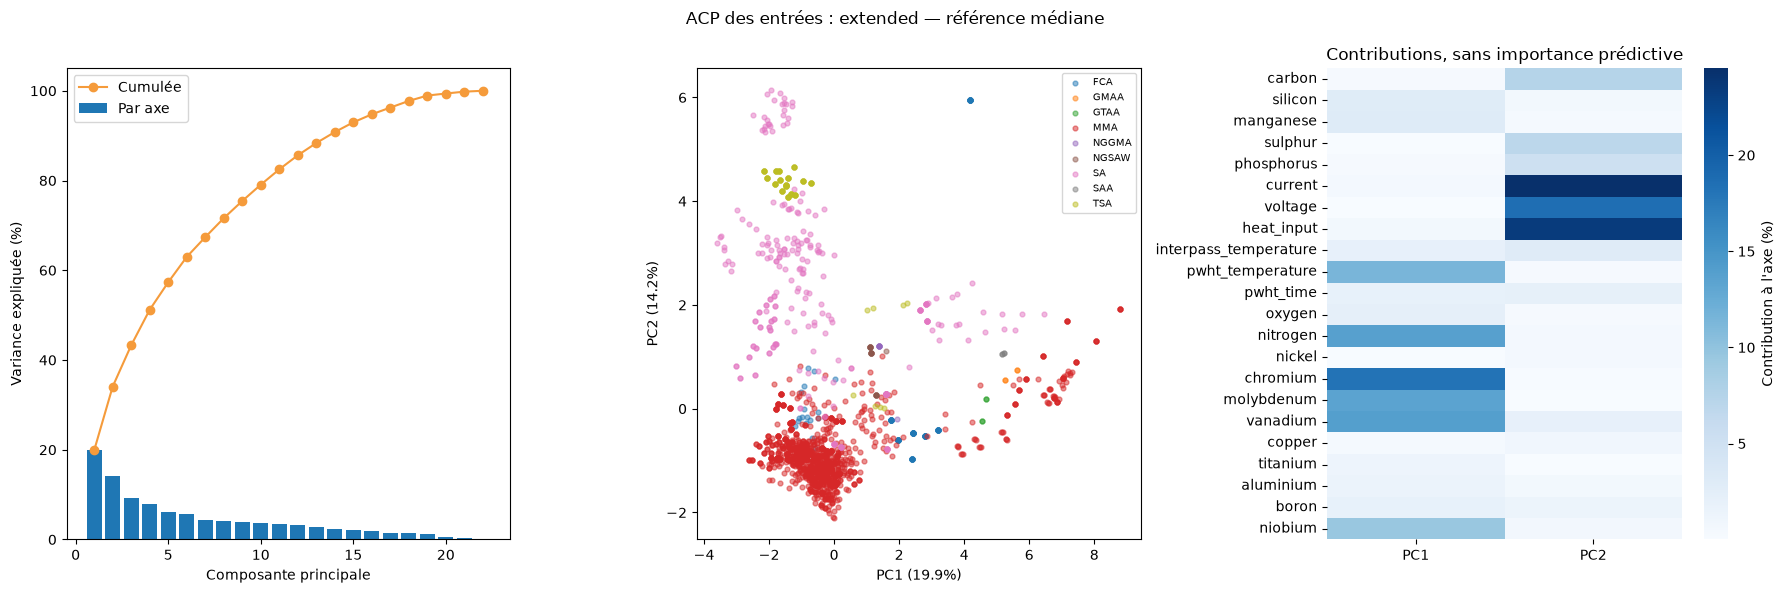

In [19]:
with threadpool_limits(limits=1):
    matrices, pcas, sensitivity, diagnostics = pca_sensitivity(audit, process, groups, max_iter=100)

pcas['tensile_complete'] = tensile_pca
display(sensitivity.round(4))
show_and_save(plot_sensitivity(sensitivity), '02_pca_sensitivity')
for family in ['core', 'extended']:
    reference_name = f'{family}_median_half_midpoint'
    result = pcas[reference_name]
    display(result.explained.round(4))
    show_and_save(plot_pca(result, process, f'ACP des entrées : {family} — référence médiane'),
                  f'02_pca_{family}')

### 5.4 Distributions et taux d'estimation

Les ECDF séparent nombres exacts utilisables, approximations et estimations.
Un amas à la médiane ou une variance fortement réduite est un signal de sensibilité,
pas une preuve que les valeurs manquantes ont été correctement retrouvées.
Les trois procédés les plus fréquents sont également examinés séparément.
Les corrélations présentes seulement après une imputation ne sont pas une preuve
indépendante de relation physique. Les cellules originales restent consultables.

median
process_median
iterative


,unit,n_exact,n_approximated,n_estimated,estimated_pct,exact_median,estimated_median,exact_std,estimated_std,estimated_at_global_median_pct,estimated_outside_bounds
variable,,,,,,,,,,,
carbon,wt%,1652,0,0,0.000,0.074,NaN,0.024,NaN,NaN,0
silicon,wt%,1652,0,0,0.000,0.320,NaN,0.112,NaN,NaN,0
manganese,wt%,1652,0,0,0.000,1.270,NaN,0.382,NaN,NaN,0
sulphur,wt%,1641,7,4,0.242,0.007,0.007,0.011,0.0,100.0,0
phosphorus,wt%,1642,0,10,0.605,0.010,0.010,0.020,0.0,100.0,0
current,A,1404,0,248,15.012,170.000,170.000,192.561,0.0,100.0,0
voltage,V,1404,0,248,15.012,21.000,21.000,12.556,0.0,100.0,0
heat_input,kJ/mm,1652,0,0,0.000,1.000,NaN,1.298,NaN,NaN,0
interpass_temperature,°C,1614,38,0,0.000,200.000,NaN,39.551,NaN,NaN,0


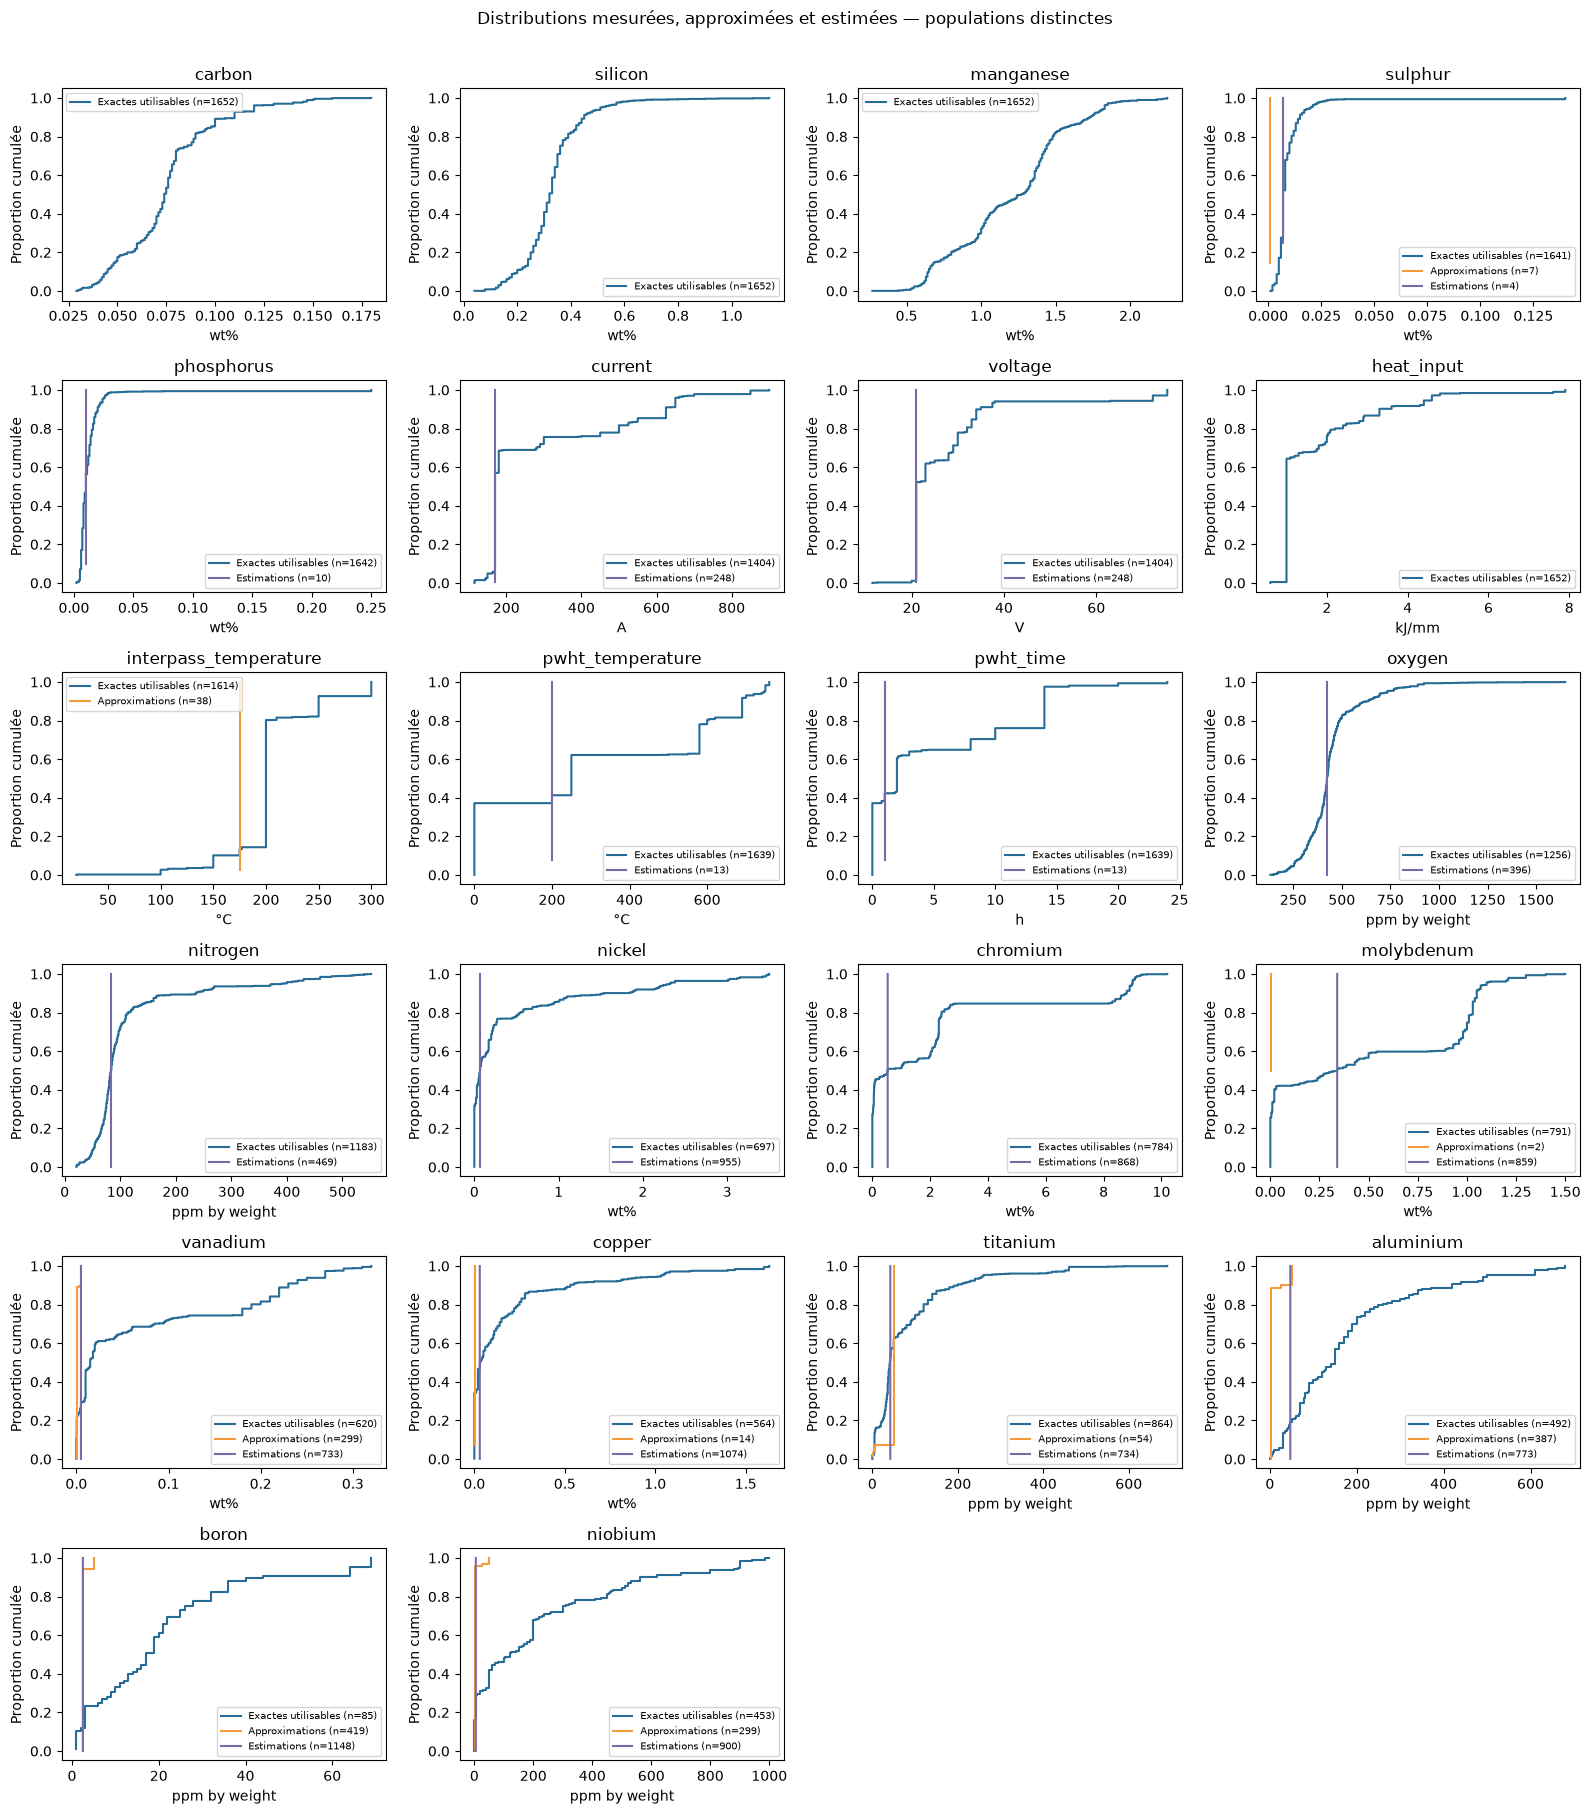

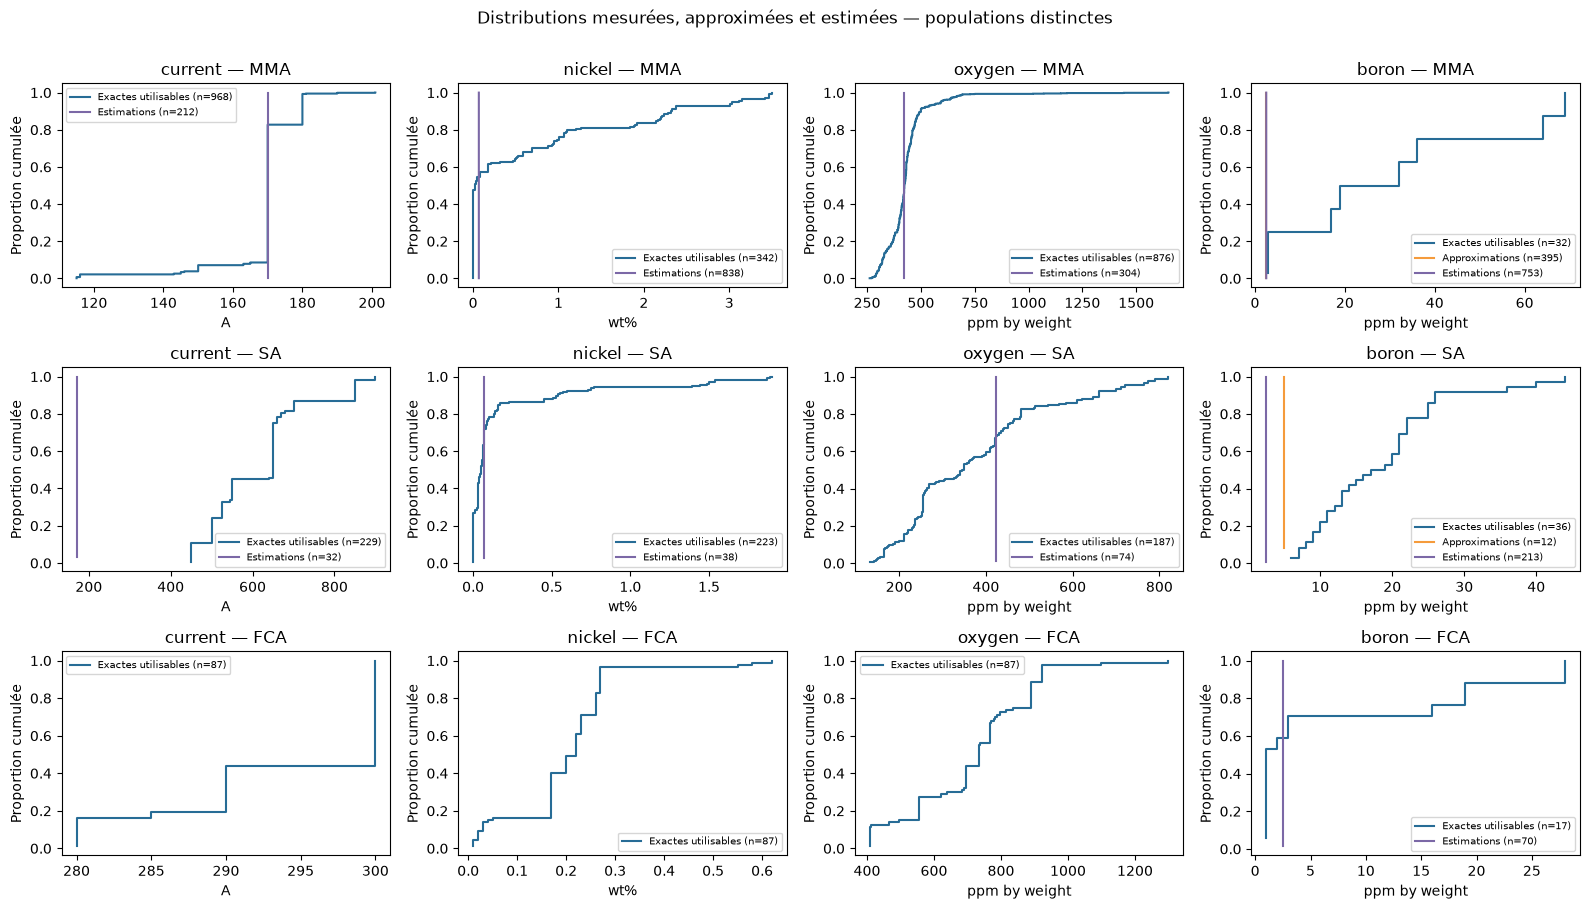

,unit,n_exact,n_approximated,n_estimated,estimated_pct,exact_median,estimated_median,exact_std,estimated_std,estimated_at_global_median_pct,estimated_outside_bounds
variable,,,,,,,,,,,
carbon,wt%,1652,0,0,0.000,0.074,NaN,0.024,NaN,NaN,0
silicon,wt%,1652,0,0,0.000,0.320,NaN,0.112,NaN,NaN,0
manganese,wt%,1652,0,0,0.000,1.270,NaN,0.382,NaN,NaN,0
sulphur,wt%,1641,7,4,0.242,0.007,0.007,0.011,0.000,100.000,0
phosphorus,wt%,1642,0,10,0.605,0.010,0.015,0.020,0.003,40.000,0
current,A,1404,0,248,15.012,170.000,170.000,192.561,161.239,87.097,0
voltage,V,1404,0,248,15.012,21.000,21.000,12.556,3.023,87.097,0
heat_input,kJ/mm,1652,0,0,0.000,1.000,NaN,1.298,NaN,NaN,0
interpass_temperature,°C,1614,38,0,0.000,200.000,NaN,39.551,NaN,NaN,0


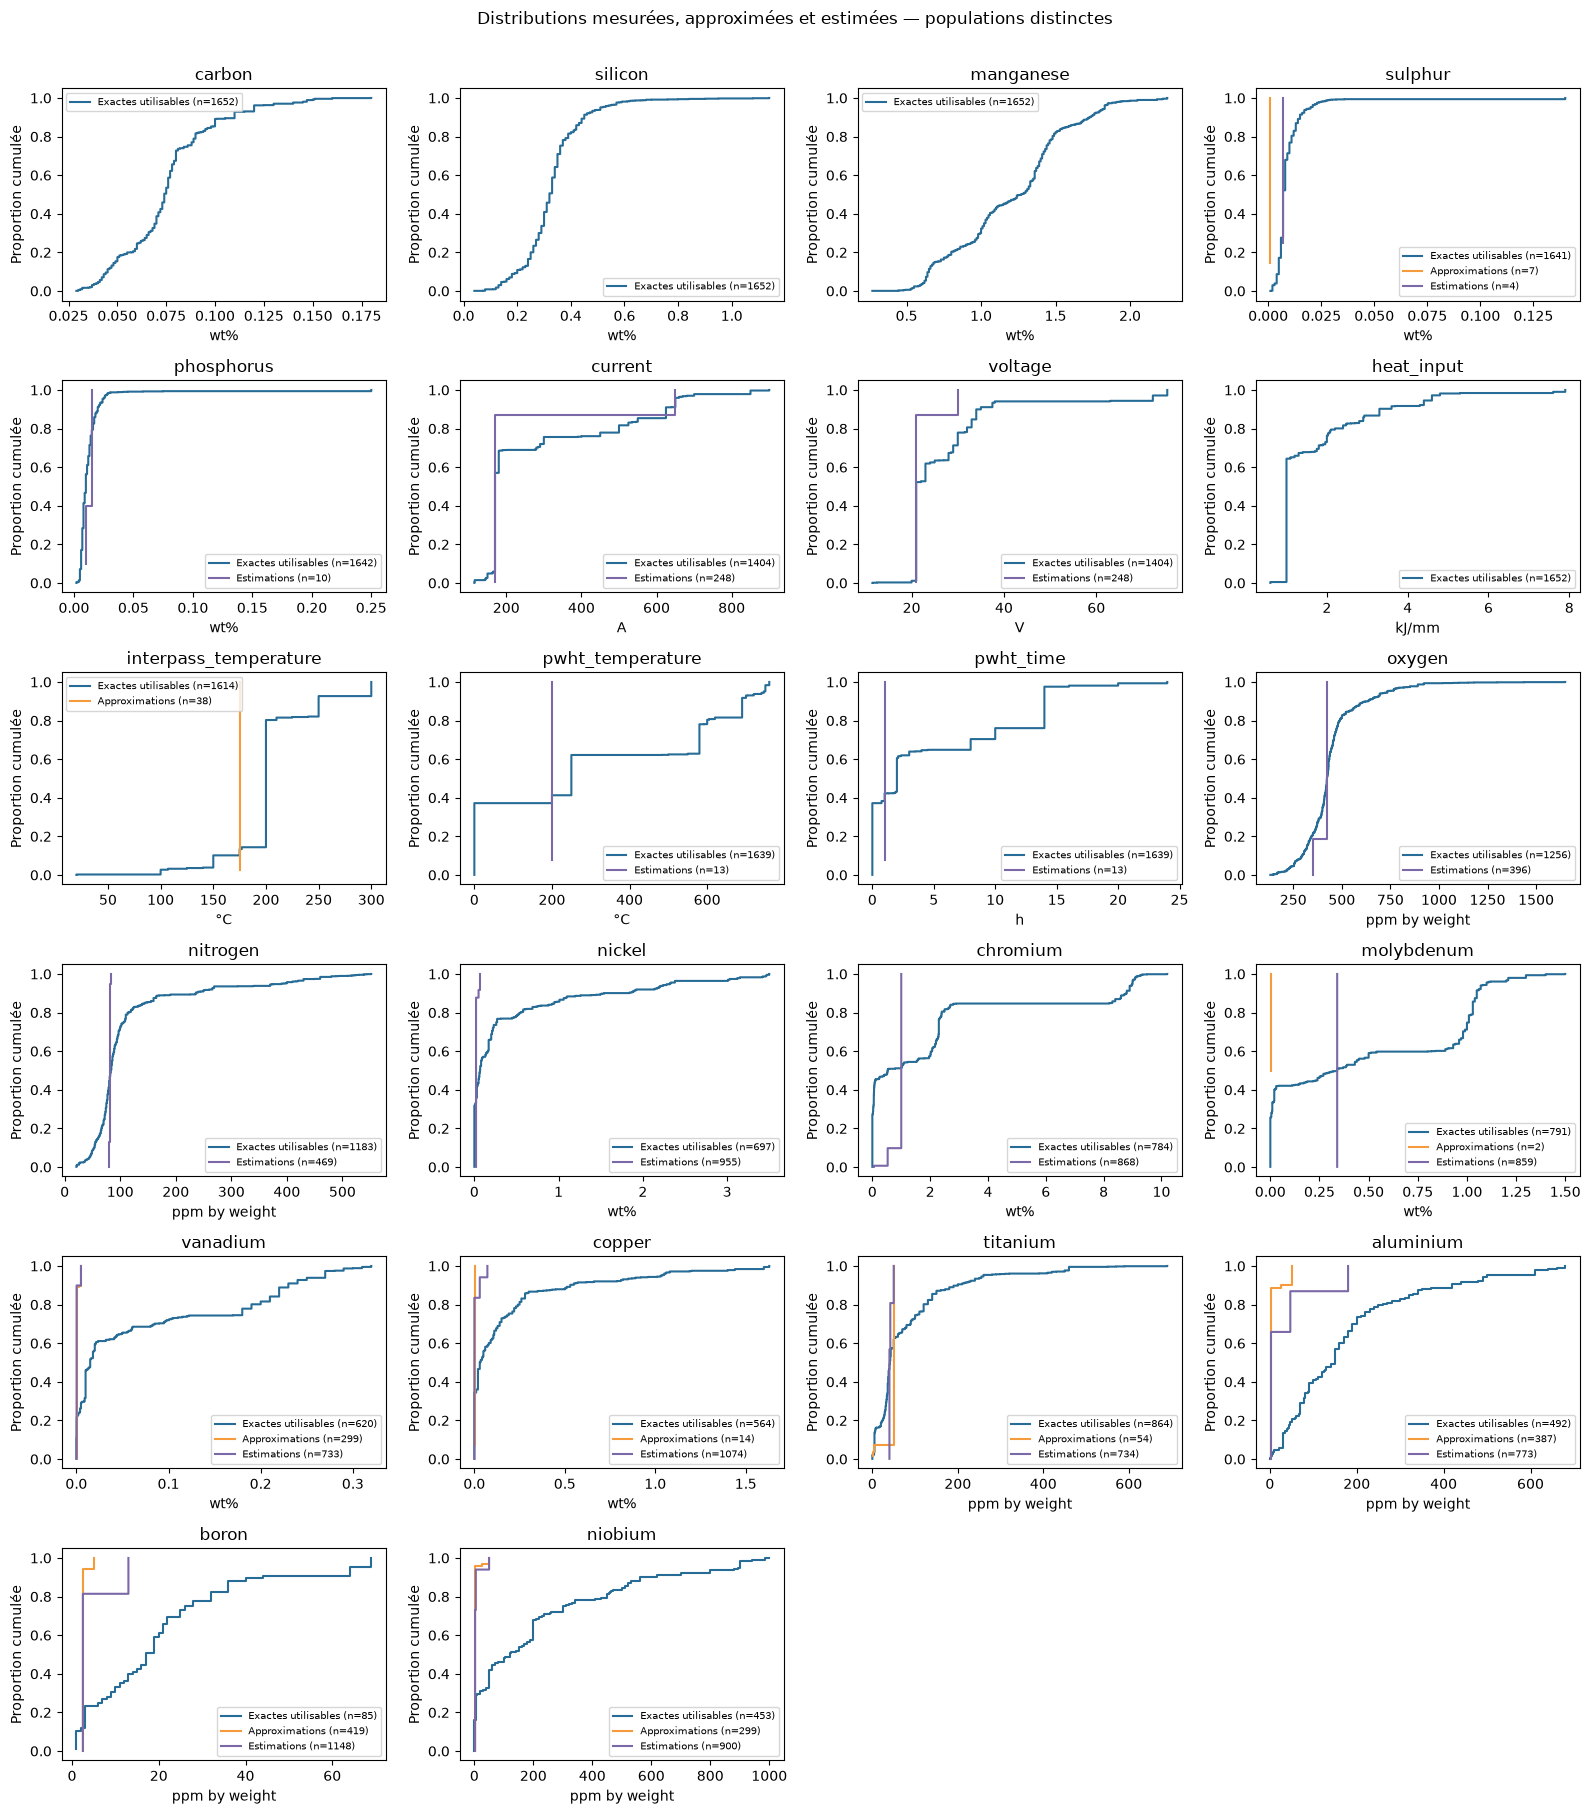

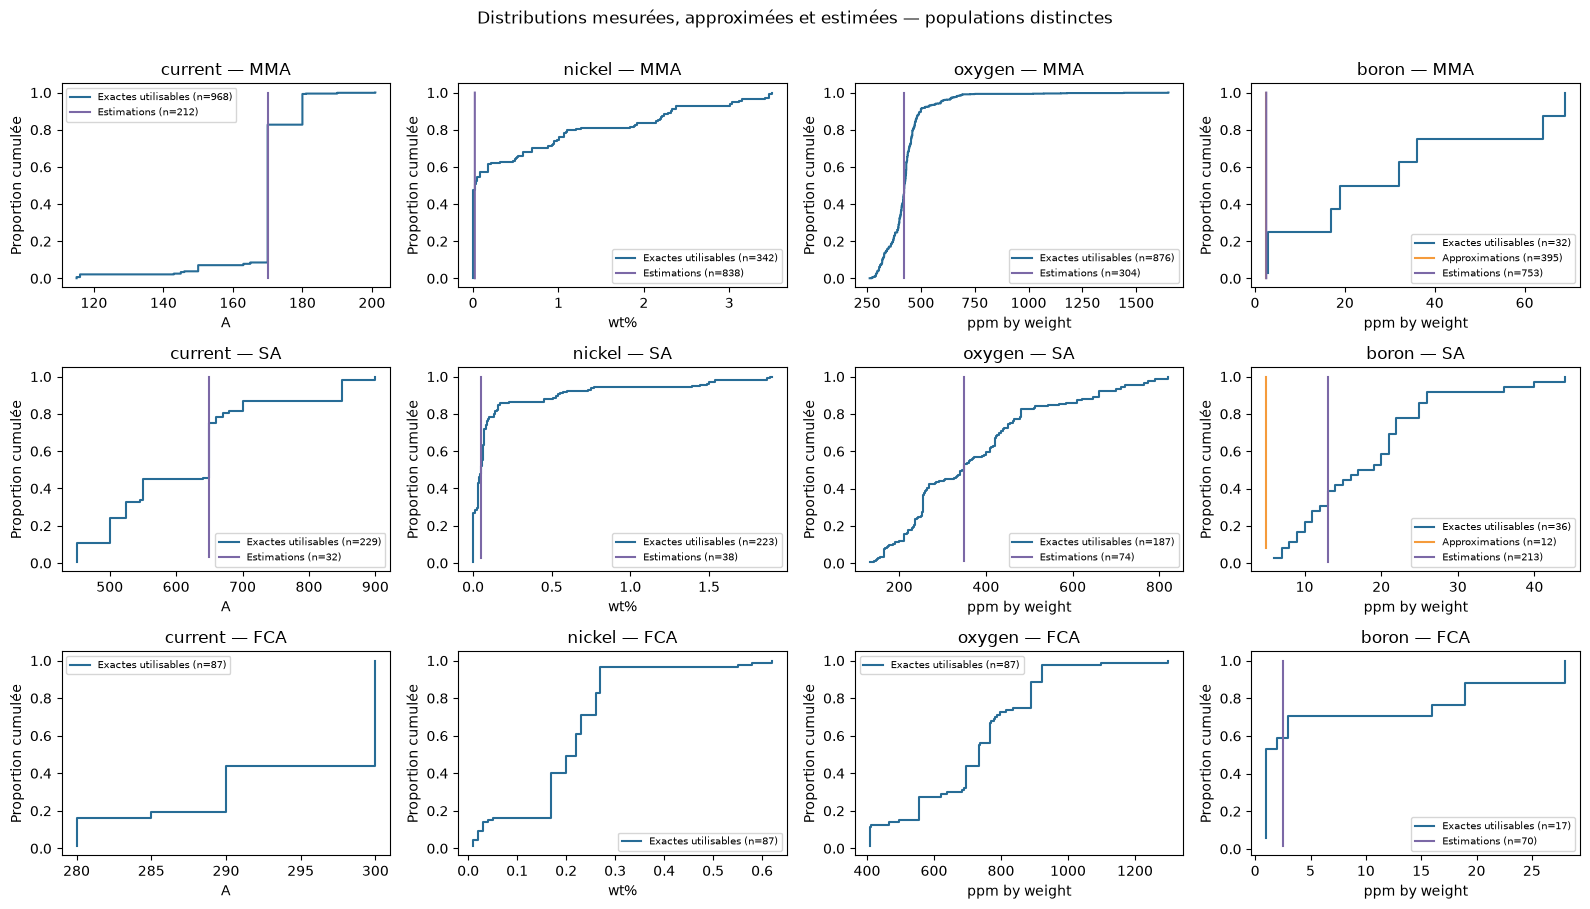

,unit,n_exact,n_approximated,n_estimated,estimated_pct,exact_median,estimated_median,exact_std,estimated_std,estimated_at_global_median_pct,estimated_outside_bounds
variable,,,,,,,,,,,
carbon,wt%,1652,0,0,0.000,0.074,NaN,0.024,NaN,NaN,0
silicon,wt%,1652,0,0,0.000,0.320,NaN,0.112,NaN,NaN,0
manganese,wt%,1652,0,0,0.000,1.270,NaN,0.382,NaN,NaN,0
sulphur,wt%,1641,7,4,0.242,0.007,0.009,0.011,0.004,0.0,0
phosphorus,wt%,1642,0,10,0.605,0.010,0.023,0.020,0.010,0.0,0
current,A,1404,0,248,15.012,170.000,182.251,192.561,121.658,0.0,0
voltage,V,1404,0,248,15.012,21.000,21.526,12.556,8.043,0.0,0
heat_input,kJ/mm,1652,0,0,0.000,1.000,NaN,1.298,NaN,NaN,0
interpass_temperature,°C,1614,38,0,0.000,200.000,NaN,39.551,NaN,NaN,0


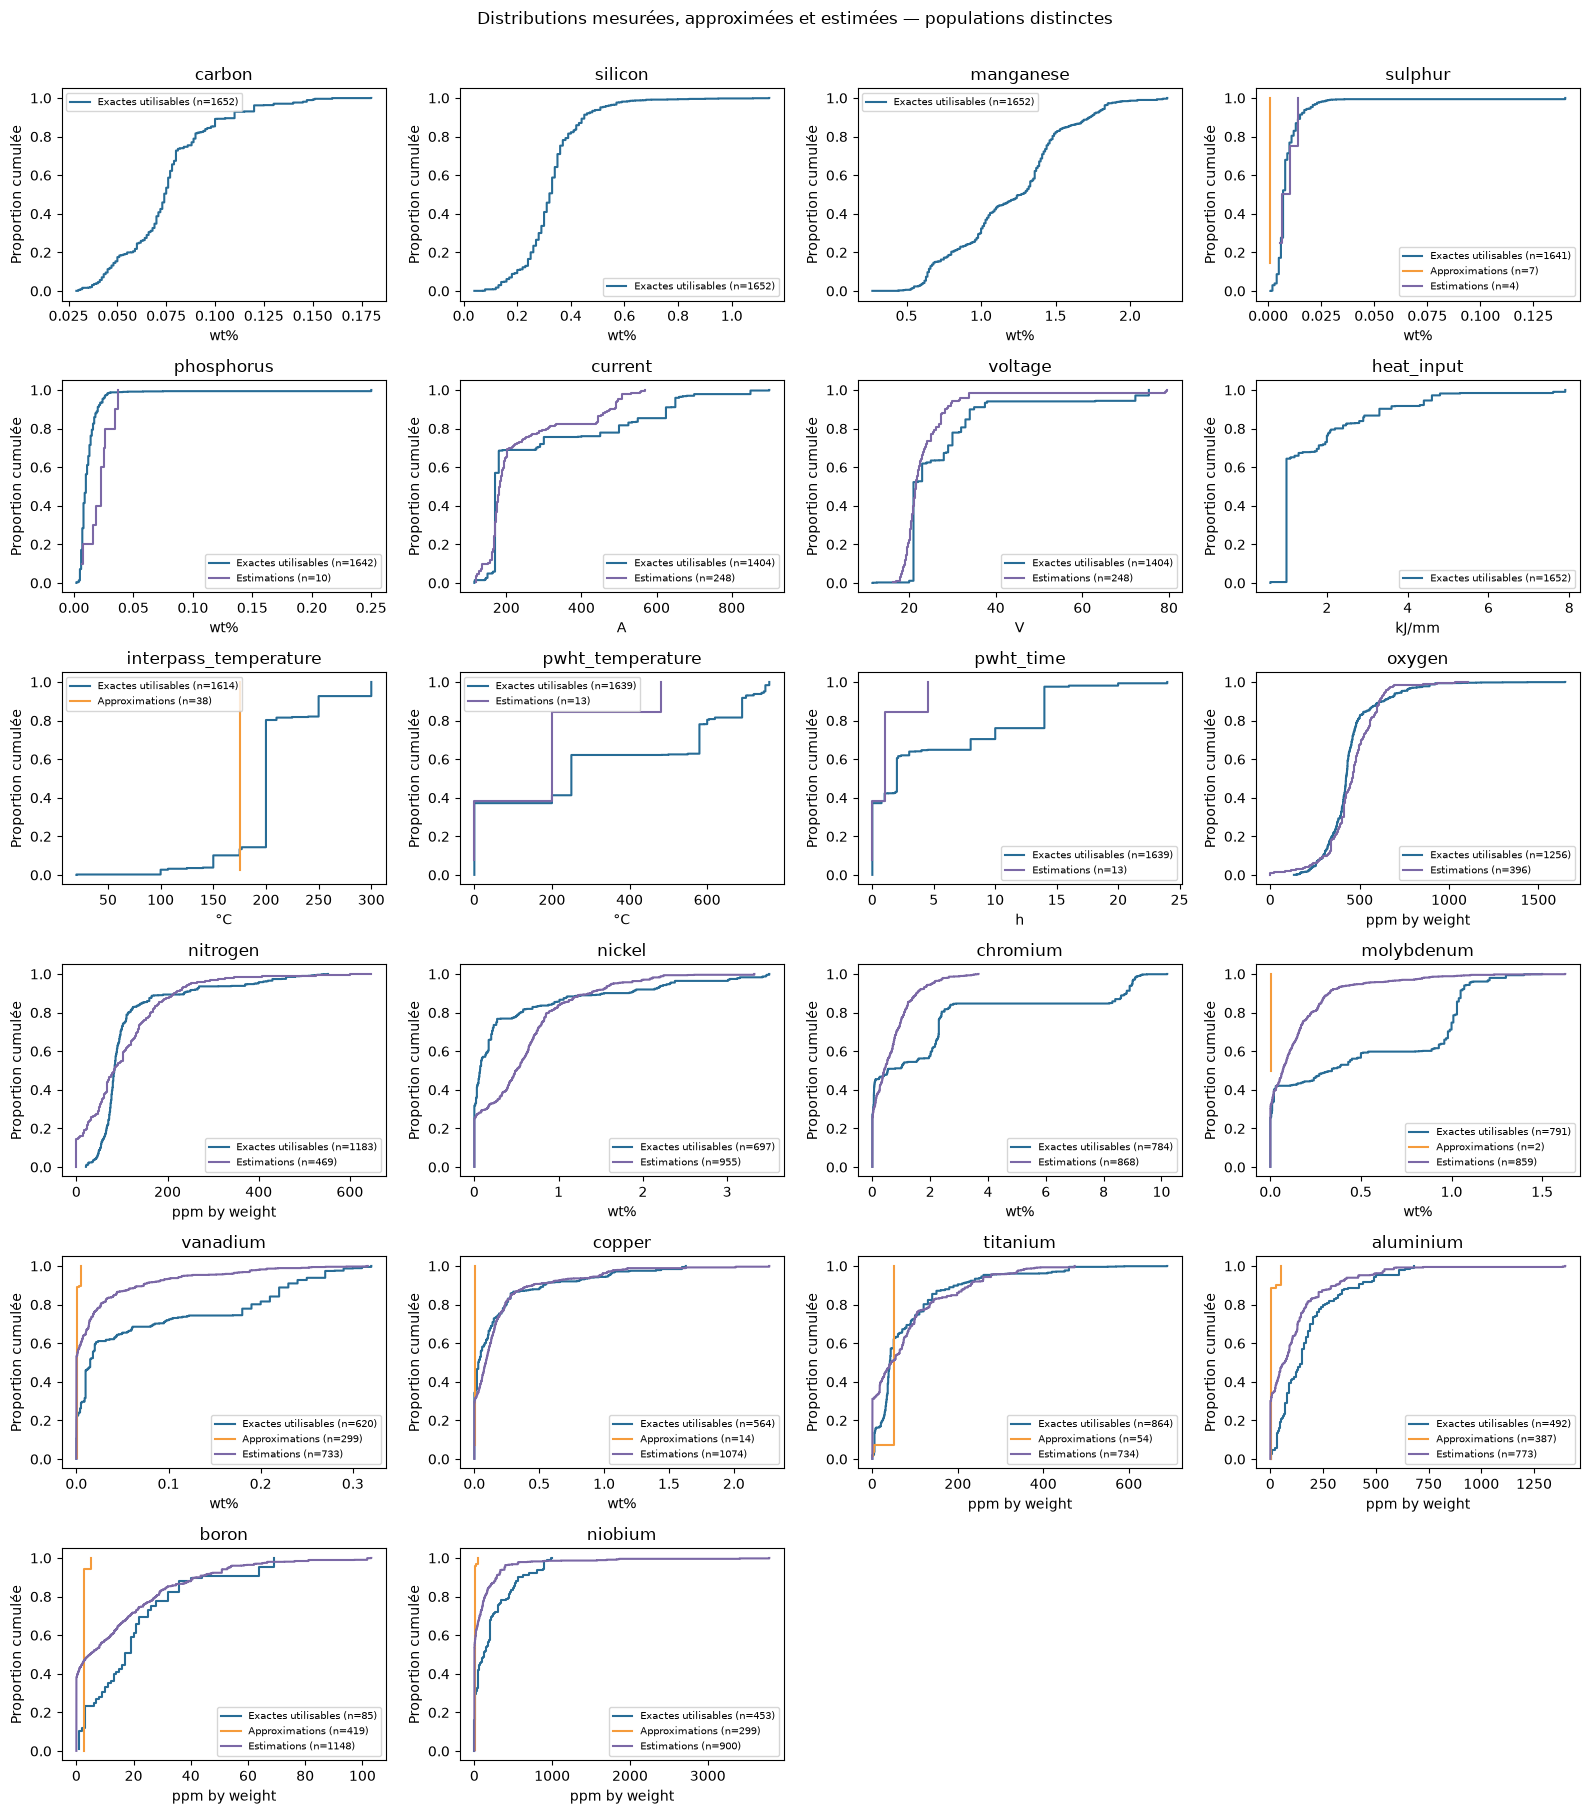

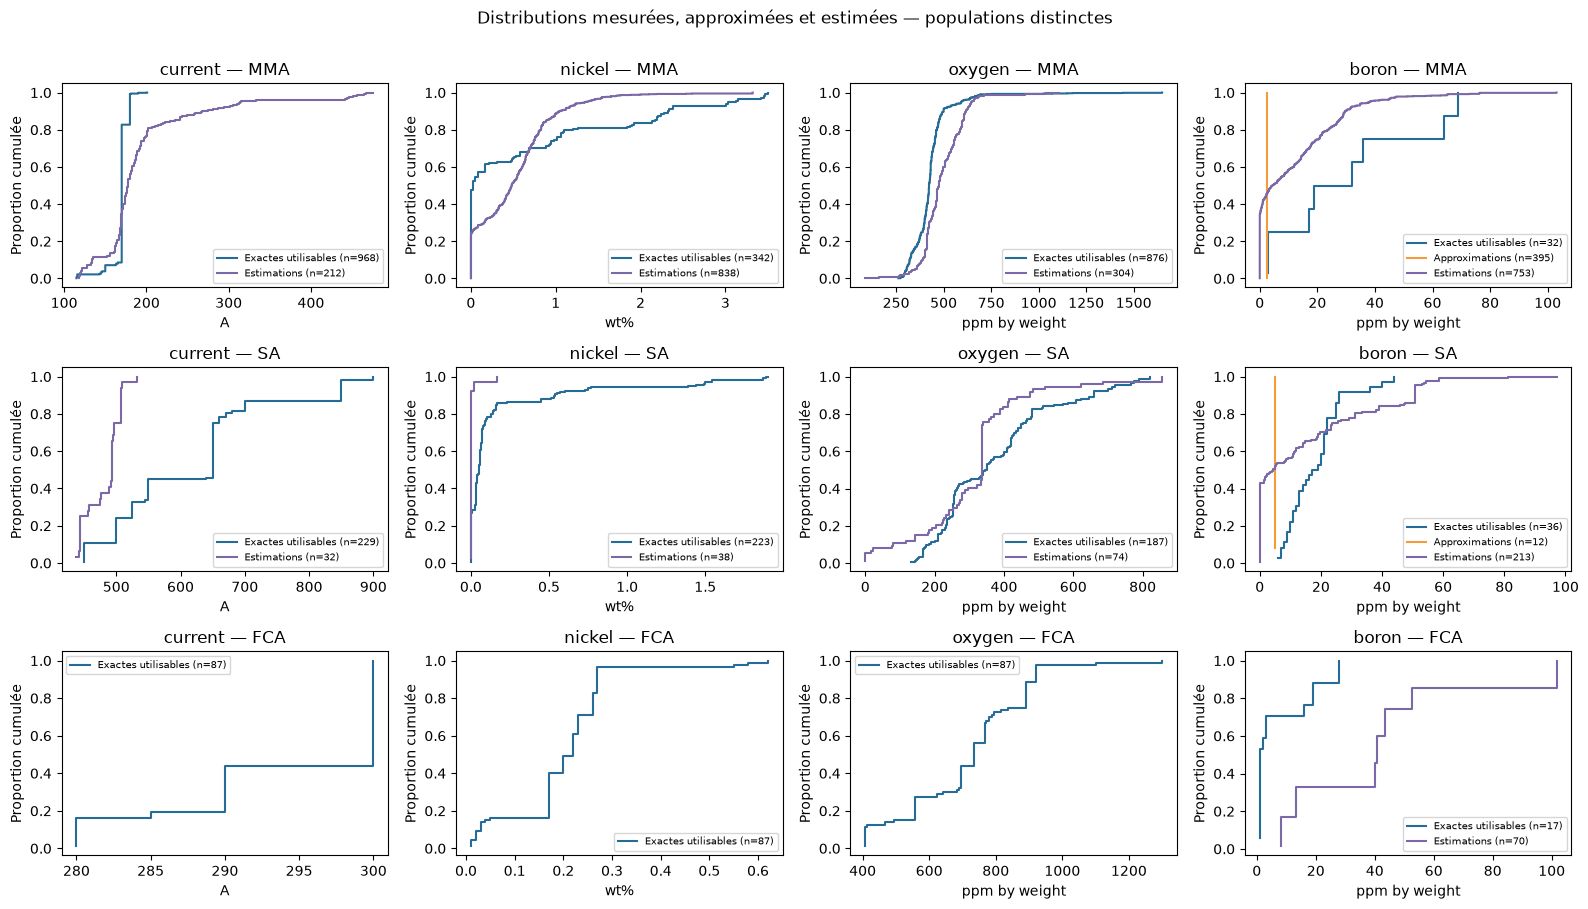

,PC1_corr_missing,PC2_corr_missing
carbon,NaN,NaN
silicon,NaN,NaN
manganese,NaN,NaN
sulphur,0.039,0.055
phosphorus,0.006,0.118
current,-0.073,-0.224
voltage,-0.073,-0.224
heat_input,NaN,NaN
interpass_temperature,NaN,NaN
pwht_temperature,-0.063,0.211


PC1             PC2      
                                        mean count      mean count
series                                                            
Alekseev&-CMnNi-1991               -1.094522     7 -0.978464     7
Birmingham                          4.836031     9  1.616310     9
Blond&-1984                         0.610461    18 -0.731983    18
Chandel&-1985                       1.229366    23  0.963196    23
Cunh-1982                          -0.671106    38  0.052788    38
Ditt                                1.589174    20  0.286405    20
EPRI-TR-101394s                     5.086638    12  0.562853    12
Es-Souni&-Cu/CMn-1990              -0.679196    12 -0.906869    12
EvHtIp1979                         -0.651078    32 -0.929144    32
Evans-Al/CMn-1990                  -0.884297    59 -0.878741    59
Evans-AlEl9Cr1Mo-1994               7.101372    13  0.561140    13
Evans-AlTi-1994                    -1.519316   114 -0.917193   114
Evans-B/9Cr1Mo-1994                 7.064732    32  1.045659    32
Evans-Cr/CMn-1989                  -0.429223    58 -1.291265    58
Evans-FelowH-1991                  -0.451920    12 -0.695806    12
Evans-Mn-1977                      -0.435098     8 -1.442112     8
Evans-Nb/Mn-1991 + Evans-V/Mn-1991  0.028306   120 -0.926950   120
Evans-Ni/CMn-1990/1991             -0.482884    58 -1.505307    58
Evans-StressRelief-1991            -0.161776   110 -0.879795   110
Evans-Ti/CMn-1992                  -1.084176    40 -1.014732    40
Evans-Ti/Mn-1992                   -0.608982    60 -1.066365    60
Evans-intpss-1978                  -0.834956    16 -1.194739    16
EvansLetter                        -0.383810   156 -1.235849   156
Ga&K-1975                          -2.124927    10  3.497651    10
Gar&K-1975                         -1.247561    56  3.662797    56
Hunt&-Di-1994                      -1.088235    16  2.583625    16
Icici&-1992                         3.033528    30  1.837242    30
Inag&-1966                          0.503955     2  0.792703     2
JorgeEtAl-1993                     -0.362461    16 -0.998937    16
Kik                                 1.768332     2  0.453867     2
Kluket-CuMnB-1994                  -3.228977    12  3.177745    12
KocakPEv-TiN-1994                  -0.780095     1 -0.751782     1
KocakPREv-TiN-1994                 -1.107510    20 -0.798222    20
Mart                                2.658063    70  0.408087    70
Natsume-1990                        1.642729     4  1.970683     4
PakSven-1990                       -0.784328    17 -0.015825    17
PantK-1990                          5.444993    54 -0.126377    54
Pat-1981                           -1.508184    79  4.364121    79
RC81033                            -1.807185     4 -0.683304     4
RR82011                            -2.130814    46  1.570162    46
RaiterGonzal-Mo-1989               -0.168165    18 -1.275027    18
Stil-TiB-1978                      -1.861616    16  5.523375    16
SurianEtAl-C-1991                  -0.134067     8 -0.498340     8
SvenGret-1990                      -1.550139    96 -0.419501    96
Sw&Rog-1973                         1.200985     4  0.094643     4
Wats-1981                          -0.567531    12  1.796559    12
Wolst-1974                          1.221431    32  0.015230    32

In [20]:
for method in ['median', 'process_median', 'iterative']:
    name = f'extended_{method}_half_midpoint'
    print(method)
    display(diagnostics[name].round(3))
    show_and_save(plot_ecdfs(prepared['extended'], matrices[name], eligibilities['extended']),
                  f'02_ecdf_{method}_all')
    show_and_save(plot_ecdfs(
        prepared['extended'], matrices[name], eligibilities['extended'], process,
        columns=['current', 'nickel', 'oxygen', 'boron'],
    ), f'02_ecdf_{method}_by_process')

# Associations avec les axes : diagnostics descriptifs, pas importance prédictive.
scores = pcas['extended_median_half_midpoint'].scores[['PC1', 'PC2']]
absence_flags = audit.status[EXTENDED_INPUTS].eq('missing').astype(int)
variable_flags = absence_flags.loc[:, absence_flags.nunique().gt(1)]
# Une colonne sans variation n'a pas de corrélation définie : afficher NaN.
absence_diagnostics = pd.DataFrame({
    'PC1_corr_missing': variable_flags.corrwith(scores.PC1),
    'PC2_corr_missing': variable_flags.corrwith(scores.PC2),
}).reindex(EXTENDED_INPUTS)
display(absence_diagnostics.round(3))
display(scores.assign(series=groups).groupby('series').agg(['mean', 'count']))

### 5.5 Exports locaux et reproductibilité

Les matrices et diagnostics dérivés sont écrits sous `data/processed/preprocessing/`,
ignoré par Git. Chaque matrice a un fichier de provenance par cellule. Le manifeste
contient le hash du brut, les versions, les paramètres et les hashes du code ; les
plis, groupes et hashes des masques sont exportés. Aucun modèle entraîné n'est sauvé.
Ces matrices sont descriptives : pour l'évaluation prédictive, repartir des valeurs
préparées avant imputation, puis ajuster la pipeline à l'intérieur des plis.

In [21]:
manifest = export_analysis(
    PROCESSED_DATA_DIR / 'preprocessing', audit, group_table, benchmarks,
    matrices, pcas, sensitivity, diagnostics, RAW_DATA_DIR / 'welddb.data',
)
print('Exports :', PROCESSED_DATA_DIR / 'preprocessing')
print('SHA-256 brut :', manifest['raw_sha256'])

Exports : /home/mohamedsalh/Documents/CS/3A/ML_Base/projet/data/processed/preprocessing
SHA-256 brut : eb46df81a454c8e549187d87c67a6e72b88676f760e8688a782c832737676ac1


## 6. Findings and modeling decisions

Summarize the selected targets, preprocessing rationale, possible grouping requirements, and limitations. Update `specs/spec.md`.

### Interprétation et limites

La référence médiane est conservée comme scénario descriptif simple, pas comme
méthode finale adoptée. L'imputation multivariée peut réduire une erreur de
reconstruction tout en orientant différemment les corrélations et les axes.
Les contributions de l'ACP décrivent la variance, pas un classement de qualité.
Aucune cible, règle métallurgique ou recommandation industrielle n'est déduite
uniquement de ces analyses. Les corrections d'unités, le sens de l'azote annoté,
la comparabilité de dureté et les sommes microstructurales restent à confirmer.

Une cible absente reste absente. Une éventuelle semi-supervision sera une étape
séparée, avec protocole inductif/transductif explicite et sans labels de validation
dans l'apprentissage ou la génération des pseudo-labels.

In [22]:
for family, result in benchmarks.items():
    scores = result.metrics.loc[result.metrics.scope.eq('all')]
    ranking = scores.groupby('method').normalized_mae.mean().sort_values()
    display(Markdown(f'**{family} — classement de reconstruction observé** (MAE normalisée moyenne)'))
    display(ranking.rename('normalized_mae').to_frame().round(4))
    name = f'{family}_median_half_midpoint'
    n80 = int((pcas[name].explained.cumulative_ratio < .8).sum() + 1)
    n90 = int((pcas[name].explained.cumulative_ratio < .9).sum() + 1)
    print(f'Référence ACP : {n80} axes pour 80 %, {n90} axes pour 90 % de variance.')
    print('Ce classement ne remplace pas les diagnostics de structure et de sensibilité.')

Référence ACP : 6 axes pour 80 %, 7 axes pour 90 % de variance.
Ce classement ne remplace pas les diagnostics de structure et de sensibilité.
Référence ACP : 11 axes pour 80 %, 14 axes pour 90 % de variance.
Ce classement ne remplace pas les diagnostics de structure et de sensibilité.


**core — classement de reconstruction observé** (MAE normalisée moyenne)

,normalized_mae
method,
iterative,0.8532
process_median,1.2541
median,1.6966


**extended — classement de reconstruction observé** (MAE normalisée moyenne)

,normalized_mae
method,
iterative,2.0089
process_median,2.0599
median,2.2532
